# Phase-field model vs MD: final figures

Figures comparing the **final phase-field runs** (`phase_field_model/` in the Zenodo record, `Le_data/` on the
workstation) with the MD droplet simulations,
in the style of the "Le plots" section of `active_droplets.ipynb`.

Inputs:
- model cells at the MD set-ups, `phase_field_model/data/md_points/cell_nk*_np*.npz` (250 K, 0.0225 µs frames; made
  with the parameters of `phase_field_model/code/config.py`, which this notebook does not use)
- model phase diagram `phase_field_model/phase_diagram/phase_final.npz` (states: oscillating, bistable_osc, steady,
  dissolved)
- MD points of the phase diagram: lists in the paths cell (the MD simulations of `cluster_size_phospho_notebook`)
- passive control of the model, `phase_field_model/data/passive/passive_1d_undriven_nk3_np15.npz`
- model runs from 16 different initial conditions at the six MD set-ups, `phase_field_model/data/initial_conditions/`
- MD cluster size and pSer vs time: `sim{ss}_size_cond_*.dat` (analysis of the droplet simulations)

All the locations are set in the paths cell from `hpa.paths` (`PHASE_FIELD_DATA` for the model data).

`SYSTEM = (N_k, N_p)` selects the system shown in the traces, limit cycle, cross-correlations and density profiles;
the same system is used for the model cell and the MD run.

Units: 10$^8$ MD steps = 1 µs (dt = 0.01 ps); model times are in µs.
Figures are saved in `plots/friction01/phase_field_comparison/`.

#### setup

In [1]:
import glob
import os
import sys
import numpy as np
from matplotlib import pyplot as plt
import scipy.signal as signal
from scipy.signal import resample
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES, PHASE_FIELD_DATA   # data locations (set HPA_DATA_ROOT to use another copy)

from hpa.cluster import read_chains_in_condensate
from hpa.plots import plot_fading_trajectory
from hpa.stats import cross_correlation, sliding_window_correlation

plt.style.use('default')
plt.style.use(STYLES + 'rates_plot.mplstyle')

In [2]:
# ---------------- paths ----------------
path_drop_fr_an = AN + 'droplet_200-tdp43-lcd/'
path_pser_an = AN + 'fixed_pser_random_droplets/'

# phase-field model data (phase_field_model/data/ in the Zenodo record, Le_data/data/ on the workstation)
cells_fine = PHASE_FIELD_DATA + 'md_points/'          # MD set-ups, 4001 frames: traces / correlations / profiles
init_dir = PHASE_FIELD_DATA + 'initial_conditions/'   # runs from different starts
passive_dir = PHASE_FIELD_DATA + 'passive/'           # passive controls (passive_1d.py)
# phase diagram with the bistable cells (the published phase_diagram.npz merges them into 'oscillating')
phase_file = PHASE_FIELD_DATA + 'phase_diagram/phase_final.npz'
fig_dir = PL + 'phase_field_comparison/'
os.makedirs(fig_dir, exist_ok=True)


def savefig(name, dpi=600):
    for ext in ('png', 'pdf'):
        plt.savefig(fig_dir + f'{name}.{ext}', dpi=dpi)

# MD points of the phase diagram as (N_p, N_k), by outcome of the MD droplet simulations (markers of the phase diagram);
# the model scripts have their own lists in phase_field_model/code/config.py, which are not used here
md = [(10, 2), (12, 2), (12, 3), (15, 3), (20, 4), (14, 4)]          # oscillating
md_steady = [(14, 2), (16, 2), (18, 2), (20, 2), (24, 2), (18, 3)]   # stable condensate
md_diss = [(8, 3), (8, 4)]                                          # dissolved
print('MD oscillating:', md, '\nMD condensate:', md_steady, '\nMD dissolved:', md_diss)

MD oscillating: [(10, 2), (12, 2), (12, 3), (15, 3), (20, 4), (14, 4)] 
MD condensate: [(14, 2), (16, 2), (18, 2), (20, 2), (24, 2), (18, 3)] 
MD dissolved: [(8, 3), (8, 4)]


#### functions

In [3]:
# pSer per chain assigned to the two protein species of the model:
#   pSer(t) = (NPSER0 * int phi_0 + NPSER1 * int phi_1) / int (phi_0 + phi_1)
# With NPSER0 = 0, NPSER1 = 24 this is exactly 24 * pfrac (pfrac = int phi_1 / int (phi_0 + phi_1)).
NPSER0 = 0
NPSER1 = 24
NCHAIN = 200

FIELDL = {'phi0': r'$\phi_0$', 'phi1': r'$\phi_1$', 'phiK': r'$\phi_K$', 'phiP': r'$\phi_P$'}


def pser_per_chain(phi0, phi1):
    '''Box-integrated pSer per chain, frame by frame (phi arrays: frames x grid).'''
    s0, s1 = phi0.sum(axis=1), phi1.sum(axis=1)
    return (NPSER0 * s0 + NPSER1 * s1) / (s0 + s1)


def b_fraction(phi0, phi1):
    '''int phi_1 / int (phi_0 + phi_1), frame by frame.'''
    return phi1.sum(axis=1) / (phi0 + phi1).sum(axis=1)


def tag(ax, s, fs=8):
    ax.set_title(s, loc='left', fontsize=fs, pad=2.5)


def condensed_chains(phi0, phi1, thr, up=8):
    '''N_chain x (fraction of total protein where phi_0 + phi_1 > thr), frame by frame.

    Each frame is spectrally upsampled by `up` (the fields are Fourier series) before the cut,
    to avoid stair-steps of several chains. up=8 as in the final_figure scripts.
    Normalised by each frame's own integral.
    '''
    tot = phi0 + phi1
    if up > 1:
        tot = resample(tot, tot.shape[1] * up, axis=1)
    dense = np.where(tot > thr, tot, 0.0).sum(axis=1)
    return NCHAIN * dense / tot.sum(axis=1)


def cell_file(nk, npp, folder=cells_fine):
    g = lambda v: ('%g' % v).replace('.', 'p')
    return folder + 'cell_nk%s_np%s.npz' % (g(nk), g(npp))


def load(fn, thr=None, up=8):
    '''Final-model cell. Box length from the stored Lstar (NOT the old 170.45 nm fallback).'''
    z = np.load(fn, allow_pickle=True)
    Ts = float(z['Tstar'])
    phi0 = np.asarray(z['phi0'], float)
    phi1 = np.asarray(z['phi1'], float)
    if thr is None:
        thr = float(z['P_thr'])
    return dict(t=np.asarray(z['t'], float) * Ts,
                chains=condensed_chains(phi0, phi1, thr, up),
                pser=pser_per_chain(phi0, phi1),
                fB=b_fraction(phi0, phi1),
                mass=np.asarray(z['mass'], float),
                phi0=phi0, phi1=phi1,
                phiK=np.asarray(z['phiK'], float), phiP=np.asarray(z['phiP'], float),
                Lnm=float(z['P_L']) * float(z['Lstar']), Tstar=Ts, thr=thr,
                period=float(z['period']) if 'period' in z.files else np.nan,
                cls=str(z['cls']) if 'cls' in z.files else '')


def cycle_times(d, i0):
    '''Dissolved, half-formed and formed frames of one oscillation after frame i0.

    formed    = second mass maximum after i0
    dissolved = mass minimum between the previous maximum and the formed one
                (in the final model the droplet never reaches zero mass)
    transient = frame on the rising branch where the mass is half-way between the two
    '''
    m = d['mass']
    pk, _ = signal.find_peaks(m[i0:], prominence=0.3 * np.ptp(m[i0:]))
    pk = pk + i0
    prev, hi = (int(pk[0]), int(pk[1])) if len(pk) > 1 else (i0, int(pk[0]))
    lo = prev + int(np.argmin(m[prev:hi + 1]))
    seg = m[lo:hi + 1]
    mid = lo + int(np.argmin(np.abs(seg - 0.5 * (m[lo] + m[hi]))))
    return lo, mid, hi

In [4]:
def best_model_shift(D, M, t0, t1):
    '''Time shift of the model (within +- half a period) that best matches the MD phase:
    maximum Pearson correlation between MD and shifted model cluster size in [t0, t1].'''
    sel = (M['t'] >= t0) & (M['t'] <= t1)
    shifts = np.linspace(-D['period'] / 2, D['period'] / 2, 1001)
    cc = np.array([np.corrcoef(M['chains'][sel], np.interp(M['t'][sel] - s, D['t'], D['chains']))[0, 1]
                   for s in shifts])
    return shifts[np.argmax(cc)], cc.max()

#### data

In [14]:
# system shown in traces, limit cycle, cross-correlations and density profiles (model cell and MD run)
SYSTEM = (3, 15)          # (N_k, N_p)
NK_SYS, NP_SYS = SYSTEM
sys_tag = f'{NK_SYS}_{NP_SYS}'

# MD run used for each system: replica, thermalization (frames of 0.04 us),
# extra frames dropped in the limit cycle only
MD_RUNS = {(2, 10): dict(ss=3, therm=25), (2, 12): dict(ss=2, therm=25), (3, 12): dict(ss=1, therm=25),
           (3, 15): dict(ss=3, therm=25, lc_skip=600), (4, 14): dict(ss=1, therm=250, lc_skip=600), 
           (4, 20): dict(ss=1, therm=50), (2, 18): dict(ss=1, therm=250)}


def md_series(nk, npp):
    r = MD_RUNS[(nk, npp)]
    t, cs, n_p = read_chains_in_condensate(path_drop_fr_an, 200, nk, npp, 'ness', r['ss'], therm=r['therm'])
    return dict(t=t / 1e8, chains=cs, pser=n_p / 200, lc_skip=r.get('lc_skip', 0))   # t in 1e8 steps = us


D = load(cell_file(NK_SYS, NP_SYS))
M = md_series(NK_SYS, NP_SYS)
M_ref = md_series(2, 18)          # reference MD oscillation in the limit-cycle plot
dt_md = M['t'][1] - M['t'][0]     # us
dt_mod = D['t'][1] - D['t'][0]    # us
print(f"model N_k={NK_SYS}, N_p={NP_SYS}: {D['cls']}, period = {D['period']:.2f} us, box = {D['Lnm']:.1f} nm, "
      f"frame spacing = {dt_mod:.4f} us")
print(f"MD    N_k={NK_SYS}, N_p={NP_SYS}: replica {MD_RUNS[SYSTEM]['ss']}, t = {M['t'][0]:.2f}-{M['t'][-1]:.2f} us, "
      f"frame spacing = {dt_md:.3f} us")

t0, t1 = 10.0, 40.0    # us: window of the time traces (MD 3/15 ends at 40 us)
t_lc = 30.0           # us: model transient dropped in the limit cycle and correlations
LC_MODEL_SKIP = 2200  # further model frames dropped in the limit cycle only
i_lc = int(np.searchsorted(D['t'], t_lc))

model N_k=3, N_p=15: oscillating, period = 5.07 us, box = 99.7 nm, frame spacing = 0.0225 us
MD    N_k=3, N_p=15: replica 3, t = 1.00-39.96 us, frame spacing = 0.040 us


In [15]:
# droplets without reactions (frozen pSer): equilibrium reference in the limit-cycle plot
dirpath_an = path_pser_an
therm_eq = 25                      # rows of the size files (0.04 us)
cs_eq, dcs_eq, np_eq = [], [], []
for npser in [5, 6, 7, 8, 8.5, 9]:
    c_all, p_all = [], []
    for ss in [1, 2, 3]:
        data = np.loadtxt(dirpath_an + f'sim{ss}_size_cond_eq_200-tdp43-lcd-{npser}pser_CAL3_fr01.dat')
        c_all.extend(data[therm_eq:, 1])
        p_all.extend(data[therm_eq:, 2])
    cs_eq.append(np.mean(c_all))
    dcs_eq.append(np.std(c_all))
    np_eq.append(p_all[0] / 200)   # frozen phosphorylation: constant
cs_eq, dcs_eq, np_eq = map(np.asarray, (cs_eq, dcs_eq, np_eq))

In [16]:
# mean pSer per chain of every MD point of the phase diagram (3 replicas each)
# thermalization in frames of 0.04 us, per (N_k, N_p)
therm_md = {(2, 14): 250, (2, 16): 250, (2, 18): 250, (2, 20): 125, (2, 24): 250, (3, 18): 125,
            (3, 8): 125, (4, 8): 250,
            (2, 10): 0, (2, 12): 0, (3, 12): 0, (3, 15): 125, (4, 20): 50, (4, 14): 250}


def mean_pser_md(points, sim_type='ness'):
    out = []
    for npp, nk in points:
        vals = []
        for ss in [1, 2, 3]:
            _, _, n_p = read_chains_in_condensate(path_drop_fr_an, 200, nk, npp, sim_type, ss,
                                                  therm=therm_md.get((nk, npp), 0))
            vals.extend(n_p)
        out.append(np.mean(vals) / 200)
    return np.asarray(out)


mean_phosphorylation_osc = mean_pser_md(md)
mean_phosphorylation = mean_pser_md(md_steady)
mean_phosphorylation_diss = mean_pser_md(md_diss)
print('mean pSer  osc:', np.round(mean_phosphorylation_osc, 2), ' steady:', np.round(mean_phosphorylation, 2),
      ' dissolved:', np.round(mean_phosphorylation_diss, 2))

mean pSer  osc: [8.25 7.91 8.63 8.36 8.37 8.97]  steady: [7.53 6.87 6.5  6.21 5.27 8.14]  dissolved: [ 9.  10.1]


In [17]:
# phase diagram of the final model
zph = np.load(phase_file, allow_pickle=True)
NK, NP = np.asarray(zph['NK'], float), np.asarray(zph['NP'], float)
nk, np_ = np.asarray(zph['N_k'], float), np.asarray(zph['N_p'], float)
cls = np.array([str(c) for c in zph['state']])          # oscillating / bistable_osc / steady / dissolved
per = np.asarray(zph['period'], float)

ik = {round(v, 2): i for i, v in enumerate(NK)}
ip = {round(v, 0): i for i, v in enumerate(NP)}
C = np.empty((len(NP), len(NK)), dtype=object)
P = np.full((len(NP), len(NK)), np.nan)
for j in range(len(nk)):
    C[ip[round(np_[j], 0)], ik[round(nk[j], 2)]] = cls[j]
    P[ip[round(np_[j], 0)], ik[round(nk[j], 2)]] = per[j]

OSC = ('oscillating', 'bistable_osc')
is_osc = np.isin(C.astype(str), OSC) & np.isfinite(P)
is_bist = (C.astype(str) == 'bistable_osc')
print({s: int((cls == s).sum()) for s in np.unique(cls)})

# MD points placed by interpolation onto the index grid
mk = np.interp([m[1] for m in md], NK, np.arange(len(NK)))
mp = np.interp([m[0] for m in md], NP, np.arange(len(NP)))
sk_ = np.interp([m[1] for m in md_steady], NK, np.arange(len(NK)))
sp_ = np.interp([m[0] for m in md_steady], NP, np.arange(len(NP)))
dk_ = np.interp([m[1] for m in md_diss], NK, np.arange(len(NK)))
dp_ = np.interp([m[0] for m in md_diss], NP, np.arange(len(NP)))
for (npp, nkk) in md + md_steady + md_diss:
    s = C[ip[round(npp, 0)], ik[round(nkk, 2)]] if (round(nkk, 2) in ik and round(npp, 0) in ip) else 'off grid'
    print(f"  MD (N_k={nkk}, N_p={npp}) -> model: {s}")

{'bistable_osc': 54, 'dissolved': 65, 'oscillating': 86, 'steady': 61}
  MD (N_k=2, N_p=10) -> model: bistable_osc
  MD (N_k=2, N_p=12) -> model: oscillating
  MD (N_k=3, N_p=12) -> model: bistable_osc
  MD (N_k=3, N_p=15) -> model: oscillating
  MD (N_k=4, N_p=20) -> model: oscillating
  MD (N_k=4, N_p=14) -> model: dissolved
  MD (N_k=2, N_p=14) -> model: steady
  MD (N_k=2, N_p=16) -> model: steady
  MD (N_k=2, N_p=18) -> model: steady
  MD (N_k=2, N_p=20) -> model: steady
  MD (N_k=2, N_p=24) -> model: steady
  MD (N_k=3, N_p=18) -> model: oscillating
  MD (N_k=3, N_p=8) -> model: dissolved
  MD (N_k=4, N_p=8) -> model: dissolved


In [18]:
# style of the phase diagrams (colours of the old notebook)
SHOW_BISTABLE = False      # hatch the bistable cells (figure names without '_no-bistable')
bist_suffix = '' if SHOW_BISTABLE else '_no-bistable'

COL = {'oscillating': '#c0392b', 'steady': '#cfe3f7',
       'dissolved': '#f6d9b0', 'diverged': '#999999', 'error': '#dddddd'}
HATCH = '////'
HATCH_EC = '#3a3a3a'

cmap_per = LinearSegmentedColormap.from_list('faded_red', ['#f5c6c6', '#d62728'])
PMAX = None          # e.g. np.percentile(P[is_osc], 95) to clip outliers of the period scale
norm_per = Normalize(vmin=np.min(P[is_osc]), vmax=PMAX if PMAX else np.max(P[is_osc]))


def phase_image(color_period=True):
    img = np.zeros((len(NP), len(NK), 3))
    for i in range(len(NP)):
        for j in range(len(NK)):
            if color_period and is_osc[i, j]:
                img[i, j] = cmap_per(norm_per(P[i, j]))[:3]
            elif str(C[i, j]) in OSC:
                img[i, j] = to_rgb(COL['oscillating'])
            else:
                img[i, j] = to_rgb(COL.get(C[i, j] or 'error', '#dddddd'))
    return img


def hatch_bistable(ax, lw=0.0):
    for i, j in zip(*np.nonzero(is_bist)):
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch=HATCH,
                               edgecolor=HATCH_EC, linewidth=lw))


def md_markers(ax, ms=6):
    ax.plot(mk, mp, '^', ms=ms, mfc='none', mec='k', mew=0.9, zorder=5)
    ax.plot(sk_, sp_, 'o', ms=ms, mfc='none', mec='k', mew=0.9, zorder=5)
    ax.plot(dk_, dp_, 's', ms=ms - 1, mfc='none', mec='k', mew=0.9, zorder=5)


def phase_axes(ax):
    sk = max(1, int(round(len(NK) / 6.0)))
    ax.set_xticks(range(0, len(NK), sk))
    ax.set_xticklabels(["%g" % NK[i] for i in range(0, len(NK), sk)])
    ax.set_yticks(range(2, len(NP), 5))
    ax.set_yticklabels(["%g" % NP[i] for i in range(2, len(NP), 5)])
    ax.set_xlabel('$N_{\\rm k}$')
    ax.set_ylabel('$N_{\\rm p}$')


def _mk(m, lab, f=0.8):
    return Line2D([], [], marker=m, ls='none', mfc='none', mec='k', mew=0.9, ms=5 * f, label=lab)


bist_patch = Patch(fc='w', ec=HATCH_EC, hatch=HATCH, label='bistable')

#### plots

Oscillation trajectory

In [19]:
# model shifted in time (within +- half a period) to match the phase of the MD run of the same system
t_shift, cc_best = best_model_shift(D, M, t0, t1)
print(f"model time shift = {t_shift:+.2f} us (period {D['period']:.2f} us), corr(N_chains MD, model) = {cc_best:.2f}")
t_mod = D['t'] + t_shift
sel_mod = (t_mod >= t0) & (t_mod <= t1)


def trace_panel(ax, t, chains, right, right_label):
    '''cluster size (left axis, blue) and pSer or B fraction (right axis, red)'''
    ax.plot(t, chains, 'b')
    ax.set_ylabel(r'$N_{\mathrm{cond}}$', color='b')
    axr = ax.twinx()
    axr.set_zorder(ax.get_zorder() - 1)
    axr.plot(t, right, 'r')
    axr.set_ylabel(right_label, color='r')
    for a in (ax, axr):
        a.patch.set_visible(False)
    return axr

model time shift = +0.13 us (period 5.07 us), corr(N_chains MD, model) = 0.24


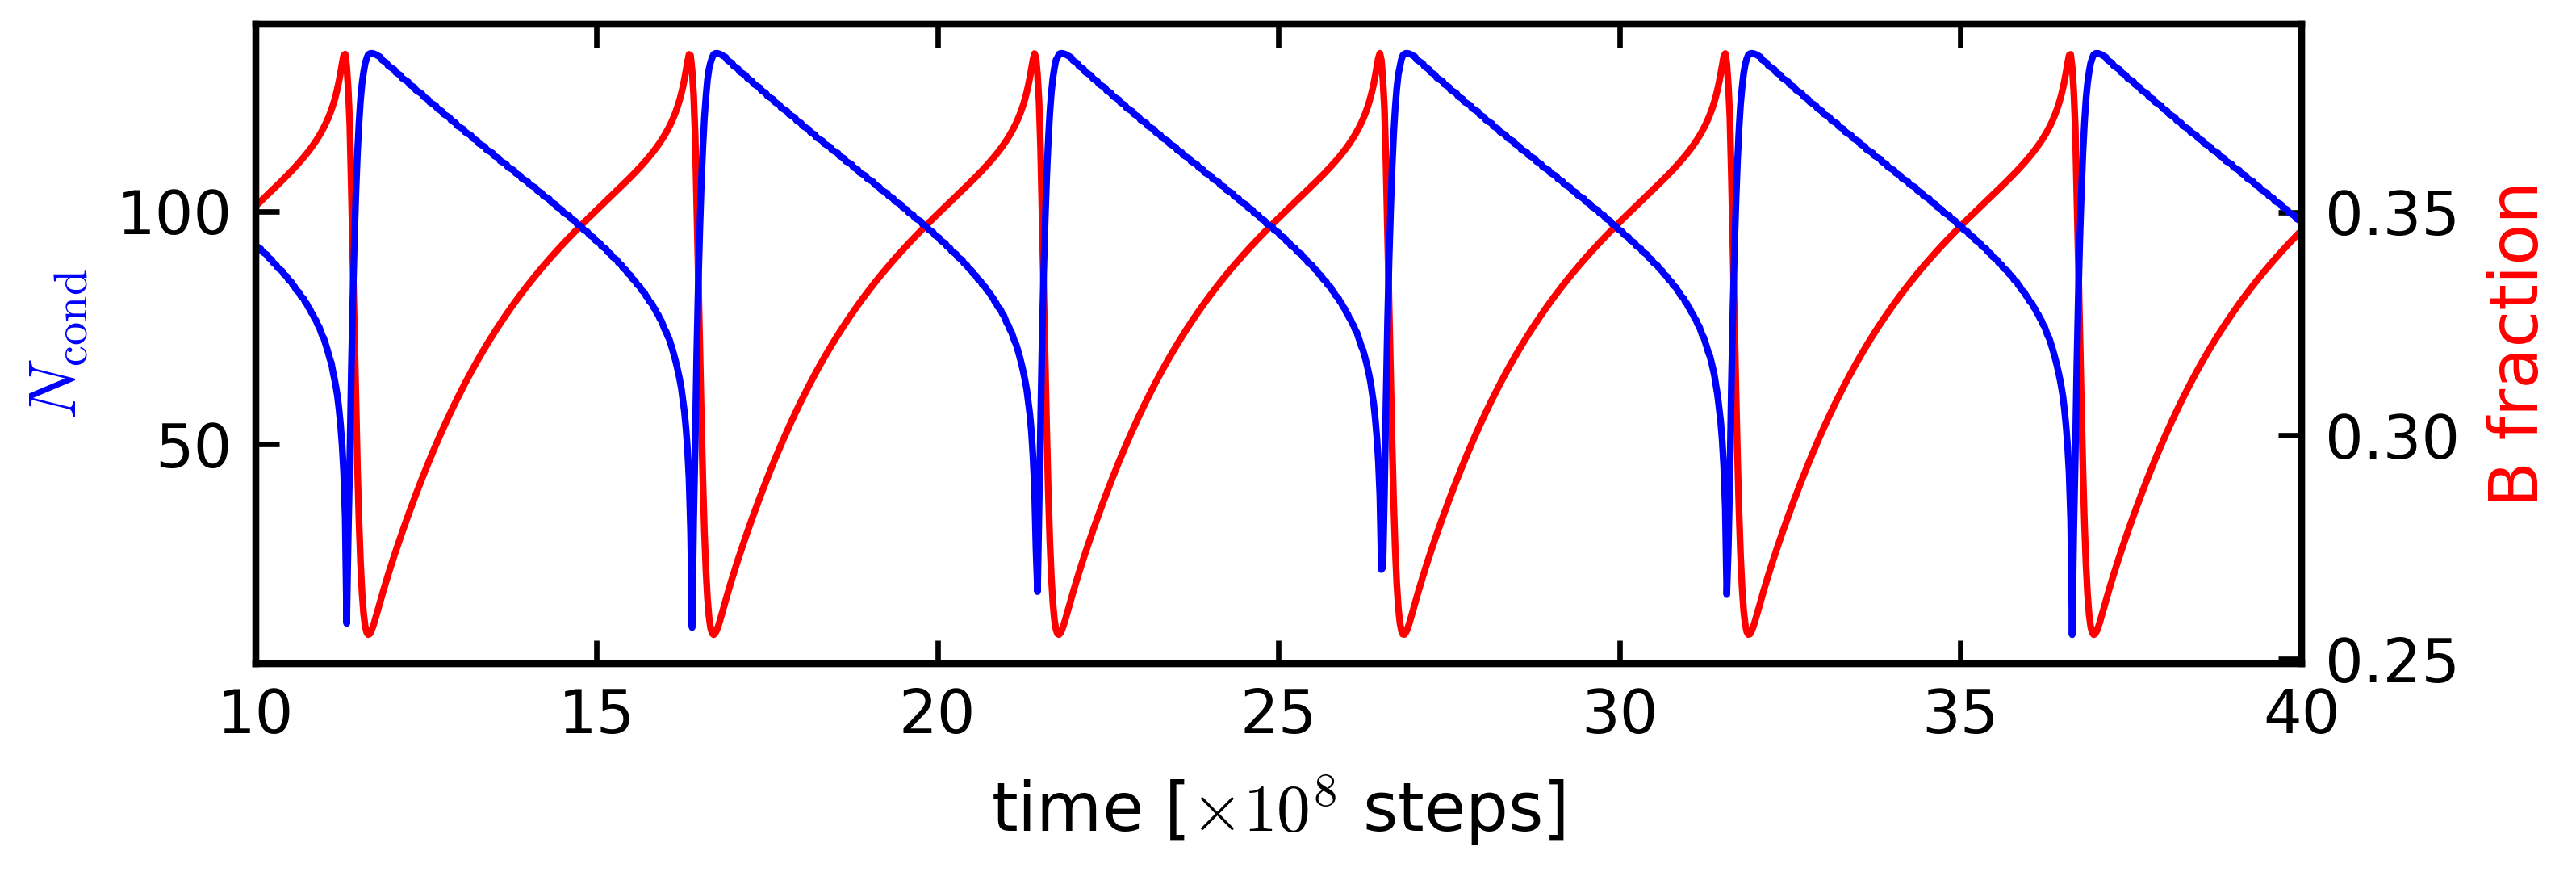

In [20]:
# model only
fig, ax = plt.subplots(1, 1, figsize=(5.6, 2.))
trace_panel(ax, t_mod[sel_mod], D['chains'][sel_mod], D['fB'][sel_mod], 'B fraction')
ax.set_xlabel(r'time [$\times 10^8$ steps]')
ax.set_xlim(t0, t1)
plt.tight_layout()
savefig(f'osc_cluster_size_200-tdp-lcd_{NK_SYS}-ck1d-open_{NP_SYS}-pp3_model_Bfraction')

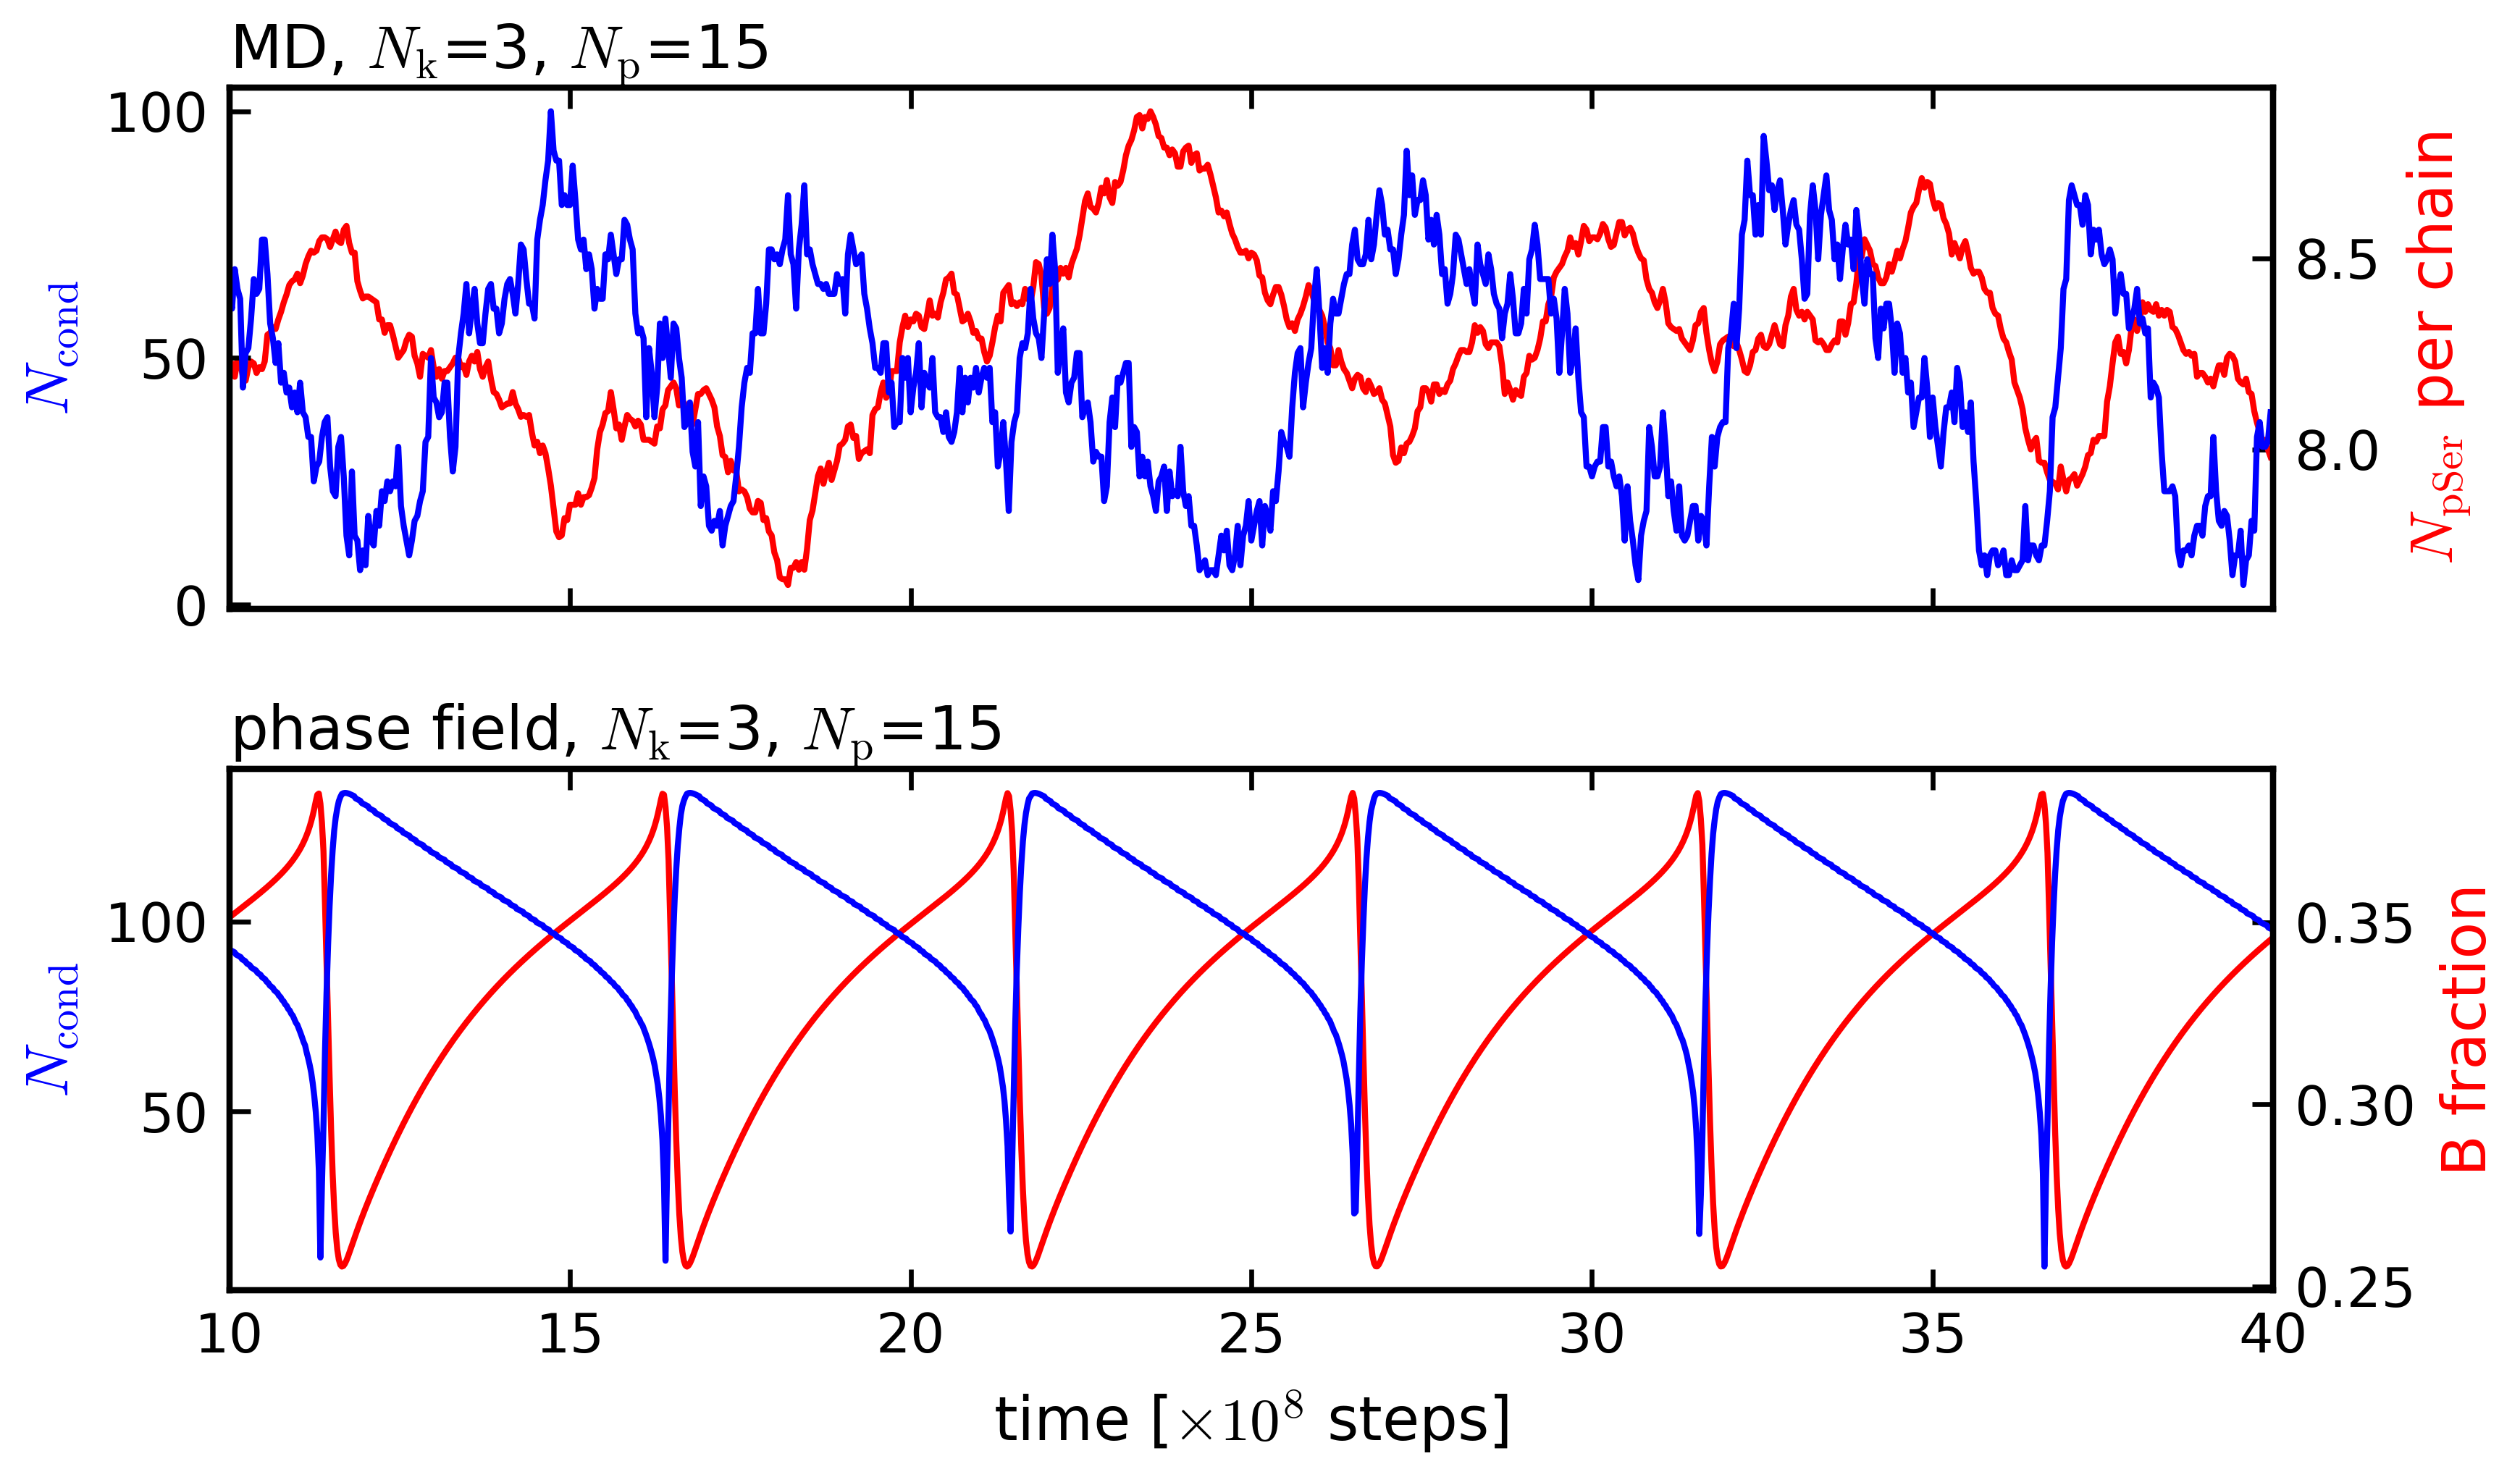

In [21]:
# MD (cluster size + pSer per chain) above, model (cluster size + B fraction) below, same window
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 3.6), sharex=True)
trace_panel(ax1, M['t'], M['chains'], M['pser'], r'$N_{\mathrm{pSer}}$ per chain')
tag(ax1, r'MD, $N_\mathrm{k}$=%d, $N_\mathrm{p}$=%d' % SYSTEM, fs=10)
trace_panel(ax2, t_mod[sel_mod], D['chains'][sel_mod], D['fB'][sel_mod], 'B fraction')
tag(ax2, r'phase field, $N_\mathrm{k}$=%d, $N_\mathrm{p}$=%d' % SYSTEM, fs=10)
ax2.set_xlabel(r'time [$\times 10^8$ steps]')
ax2.set_xlim(t0, t1)
plt.tight_layout()
savefig(f'osc_cluster_size_200-tdp-lcd_{NK_SYS}-ck1d-open_{NP_SYS}-pp3_MD_vs_model_Bfraction')

passive_1d_undriven_nk3_np15.npz: last 20%: 164.0 chains, B fraction 0.065


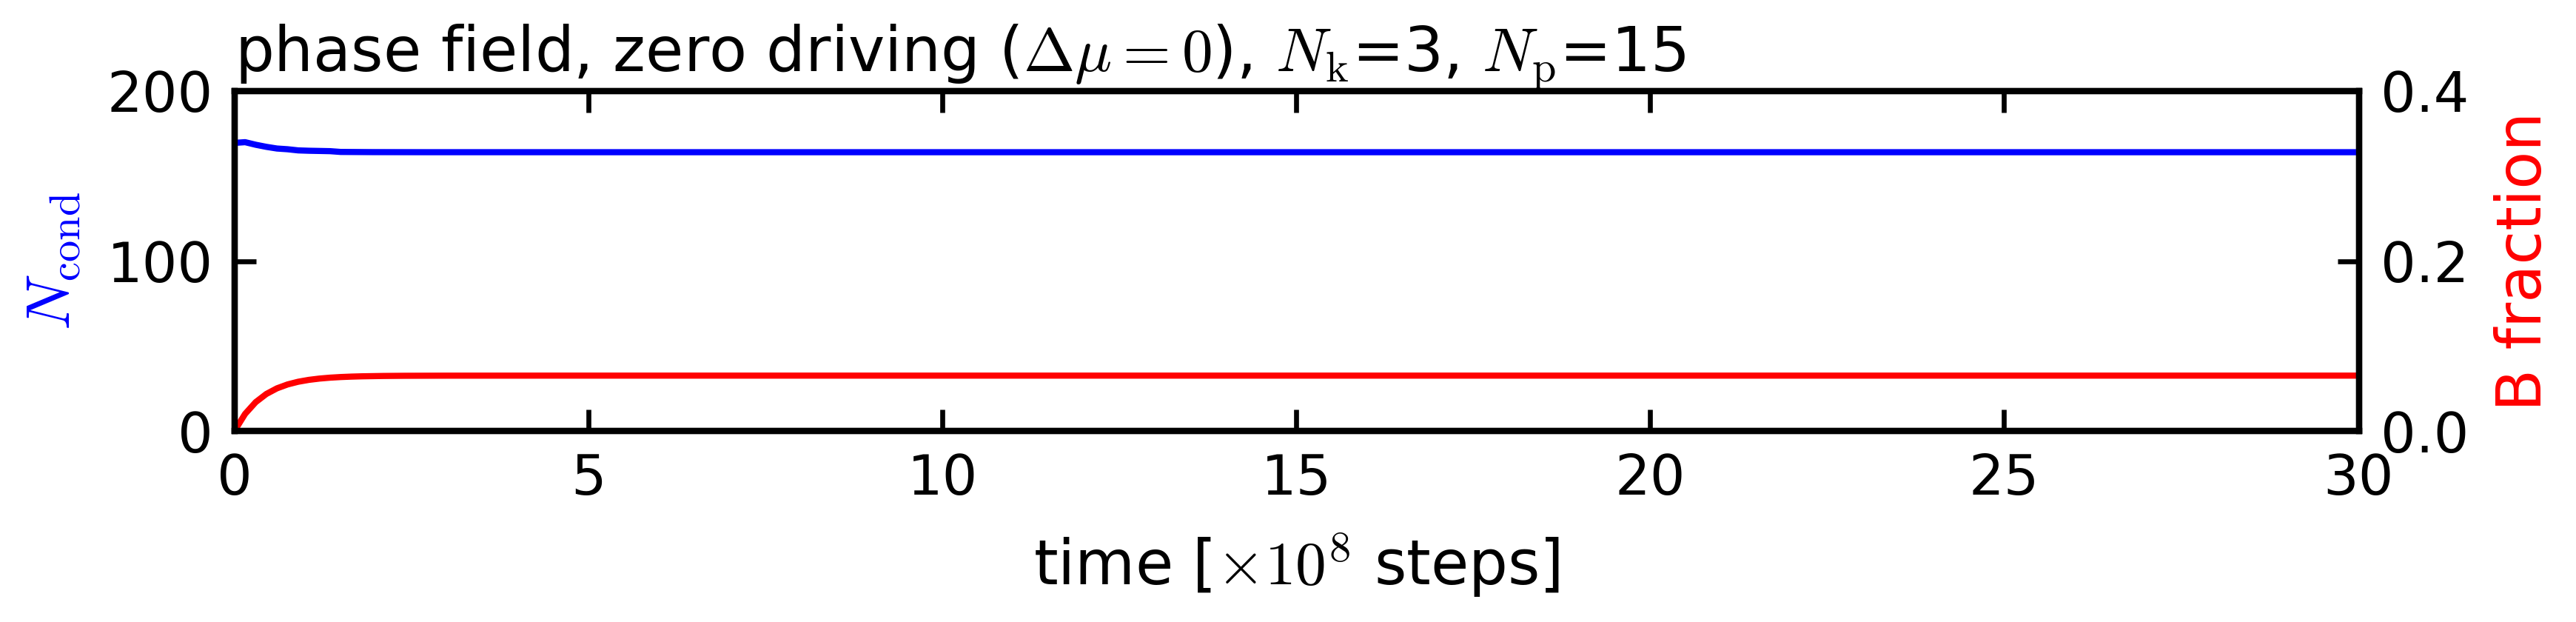

In [27]:
# passive control of the continuum model, started from a condensate:
#   undriven: enzymes of 3/15, zero driving (Delta mu = 0)
#   (passive_1d_noreact.npz: reactions off, no enzymes, N_k = N_p = 0)
# chains from the saved phi_0, phi_1 frames (every 0.15 us) with the stored threshold P_thr, like the driven cells
PASSIVE = [('passive_1d_undriven_nk3_np15.npz', r'zero driving ($\Delta\mu=0$)')]
# PASSIVE += [('passive_1d_noreact.npz', 'reactions off, no enzymes')]

fig, axs = plt.subplots(len(PASSIVE), 1, figsize=(6, 1.6 * len(PASSIVE)), sharex=True, squeeze=False)
axs = axs[:, 0]
for ax, (fn, lab) in zip(axs, PASSIVE):
    zp = np.load(passive_dir + fn, allow_pickle=True)
    fr = np.asarray(zp['frames'], float)                 # frames x (phi0, phi1, phiK, phiP) x grid
    tp = np.asarray(zp['t_frames_us'], float)
    ch = condensed_chains(fr[:, 0], fr[:, 1], float(zp['P_thr']))
    fBp = b_fraction(fr[:, 0], fr[:, 1])
    axr = trace_panel(ax, tp, ch, fBp, 'B fraction')
    ax.set_ylim(0, 200)
    axr.set_ylim(0, 0.4)                                 # same range as the driven model (0.25-0.38)
    tag(ax, r'phase field, %s, $N_\mathrm{k}$=%g, $N_\mathrm{p}$=%g' % (lab, float(zp['N_k']), float(zp['N_p'])), fs=10)
    late = tp > 0.8 * tp[-1]
    print(f'{fn}: last 20%: {ch[late].mean():.1f} chains, B fraction {fBp[late].mean():.3f}')
axs[-1].set_xlabel(r'time [$\times 10^8$ steps]')
axs[-1].set_xlim(tp[0], tp[-1])
plt.tight_layout()
savefig('passive_model_cluster_size_Bfraction')

Limit cycle

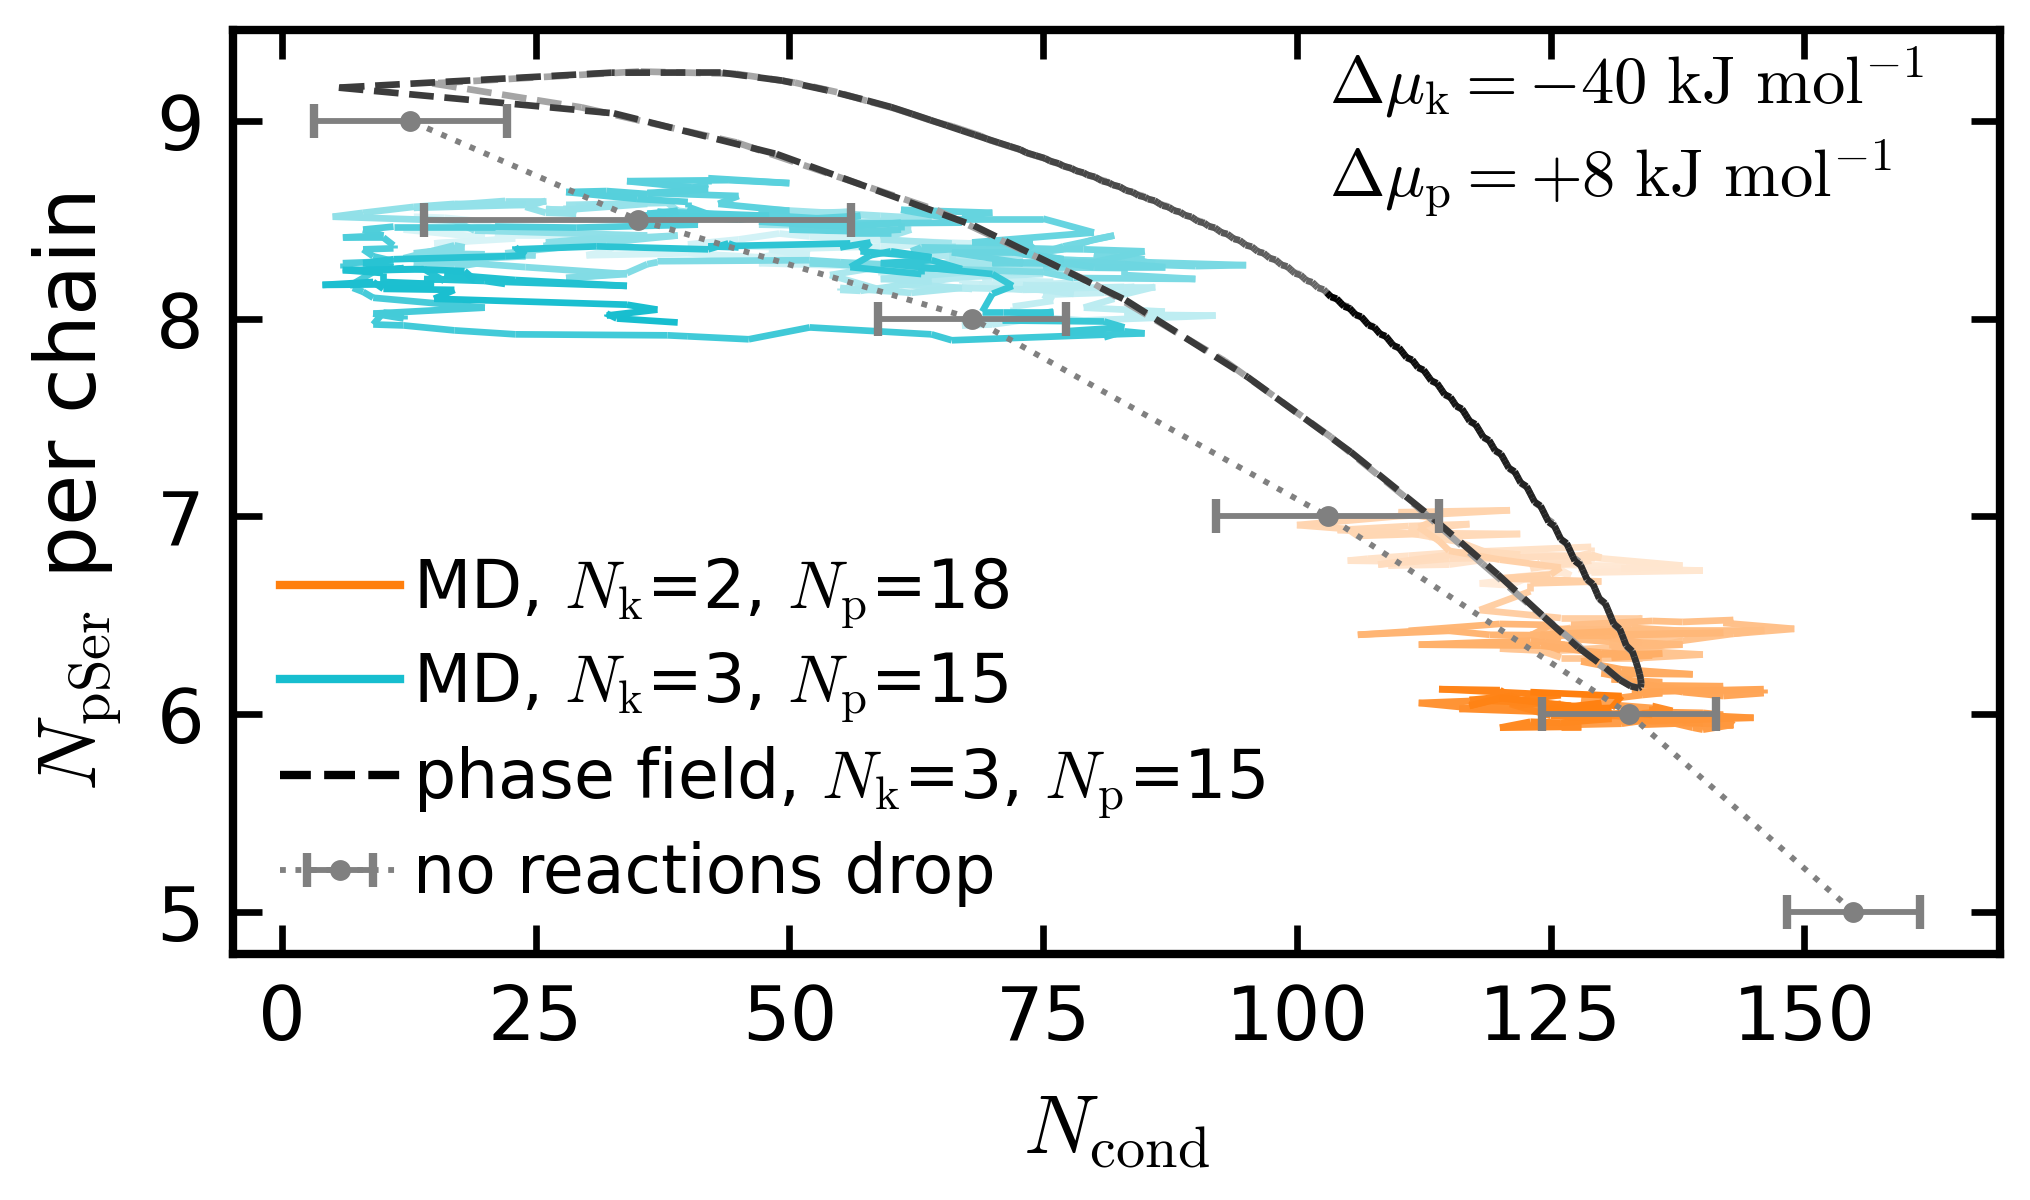

In [22]:
fig, ax = plt.subplots(figsize=(3.8, 2))

if SYSTEM != (2, 18):
    plot_fading_trajectory(ax, M_ref['chains'], M_ref['pser'], 'tab:orange', label='MD, $N_\mathrm{k}$=2, $N_\mathrm{p}$=18',
                           plot_mean=False)
plot_fading_trajectory(ax, M['chains'], M['pser'], 'tab:cyan', label='MD, $N_\mathrm{k}$=%d, $N_\mathrm{p}$=%d' % SYSTEM,
                       plot_mean=False, therm=M['lc_skip'])
plot_fading_trajectory(ax, D['chains'][i_lc:], D['pser'][i_lc:], 'k',
                       label='phase field, $N_\mathrm{k}$=%d, $N_\mathrm{p}$=%d' % SYSTEM, plot_mean=False, linestyle='--',
                       therm=LC_MODEL_SKIP)
ax.errorbar(cs_eq, np_eq, xerr=dcs_eq, capsize=2, fmt='.:', color='grey', lw=0.7, label='no reactions drop')

ax.autoscale()
ax.legend(frameon=False)
ax.set_xlabel(r'$N_{\mathrm{cond}}$')
ax.set_ylabel(r'$N_{\mathrm{pSer}}$ per chain')
# position in axes coordinates, so it does not depend on the data range
ax.text(0.62, 0.92, r'$\Delta \mu_\mathrm{k}=-40~\mathrm{kJ}~\mathrm{mol}^{-1}$', fontsize=8, transform=ax.transAxes)
ax.text(0.62, 0.82, r'$\Delta \mu_\mathrm{p}=+8~\mathrm{kJ}~\mathrm{mol}^{-1}$', fontsize=8, transform=ax.transAxes)
savefig(f'limit_cycles_drop_cond_size_model_compare_{sys_tag}')

Limit cycles from different initial conditions

Phase-field runs of the six MD set-ups started from 16 different condensates (droplets of different size,
pre-phosphorylated, kinase in the dilute phase, several droplets, restarts on the cycle) instead of the slab.
- phase portraits: first `N_LAPS` periods of five of the starts (white -> colour as time goes on, dot = start) and the limit cycle
  of the slab start (black, last two periods)
- deviation of period, mean pSer and pSer amplitude of all 15 droplet starts from the slab start

In [53]:
# phase-field runs of the six MD set-ups from 16 different starts (scan_init_md.py, T = 90 us);
# C_slab is the start of the phase diagram and of the cells above
INIT_POINTS = [(2, 10), (2, 12), (3, 12), (3, 15), (3, 18), (4, 20)]
INIT_DROPLET = ('C_', 'D_', 'E_', 'F_', 'G_')     # every start except the slab
# starts shown in the phase portraits
INIT_SHOWN = [('C_size0.25', r'small droplet, 0.25$\times$', 'tab:blue'),
              ('D_size1_p0.4', r'pre-phosphorylated, $p=0.4$', 'tab:red'),
              ('E_kin_dilute', 'kinase in dilute phase', 'tab:green'),
              ('F_drop3_s0', 'three droplets', 'tab:purple'),
              ('G_cyc_min', 'restart at cycle minimum', 'tab:orange')]
N_LAPS = 2                # each start shown for N_LAPS periods of its set-up (all reach the cycle within ~1 us)


def init_file(nk, npp, label):
    g = lambda v: ('%g' % v).replace('.', 'p')
    return init_dir + 'run_nk%s_np%s_%s.npz' % (g(nk), g(npp), label)


def init_labels(nk, npp):
    '''Labels of all the starts available for one set-up.'''
    n = len(os.path.basename(init_file(nk, npp, ''))) - len('.npz')     # length of 'run_nk*_np*_'
    return sorted(os.path.basename(f)[n:-len('.npz')] for f in glob.glob(init_file(nk, npp, '*')))


def load_init(nk, npp, label):
    '''Run from one initial condition. Only 300 field frames are stored, so the condensate size is taken from
    the finer mass time series, N_cond = N_chain M / (phi_bar L): it matches condensed_chains of the fields
    (corr. 0.999, same mean). Period, mean and amplitude of pSer over a whole number of periods at the end.'''
    z = np.load(init_file(nk, npp, label), allow_pickle=True)
    t = np.asarray(z['t'], float) * float(z['Tstar'])
    pser = NPSER1 * np.asarray(z['pfrac'], float)
    period = float(z['period'])
    zc = np.load(cell_file(nk, npp))                                # same parameters as the slab_fine cell
    phi_L = float(zc['P_phi']) * float(zc['P_L'])
    if np.isfinite(period) and period > 0:
        w = t >= t[-1] - max(1, int(0.4 * t[-1] // period)) * period
    else:
        w = t >= 0.6 * t[-1]
    return dict(t=t, chains=NCHAIN * np.asarray(z['mass'], float) / phi_L, pser=pser,
                period=period, cls=str(z['cls']), pmean=pser[w].mean(), pamp=np.ptp(pser[w]))

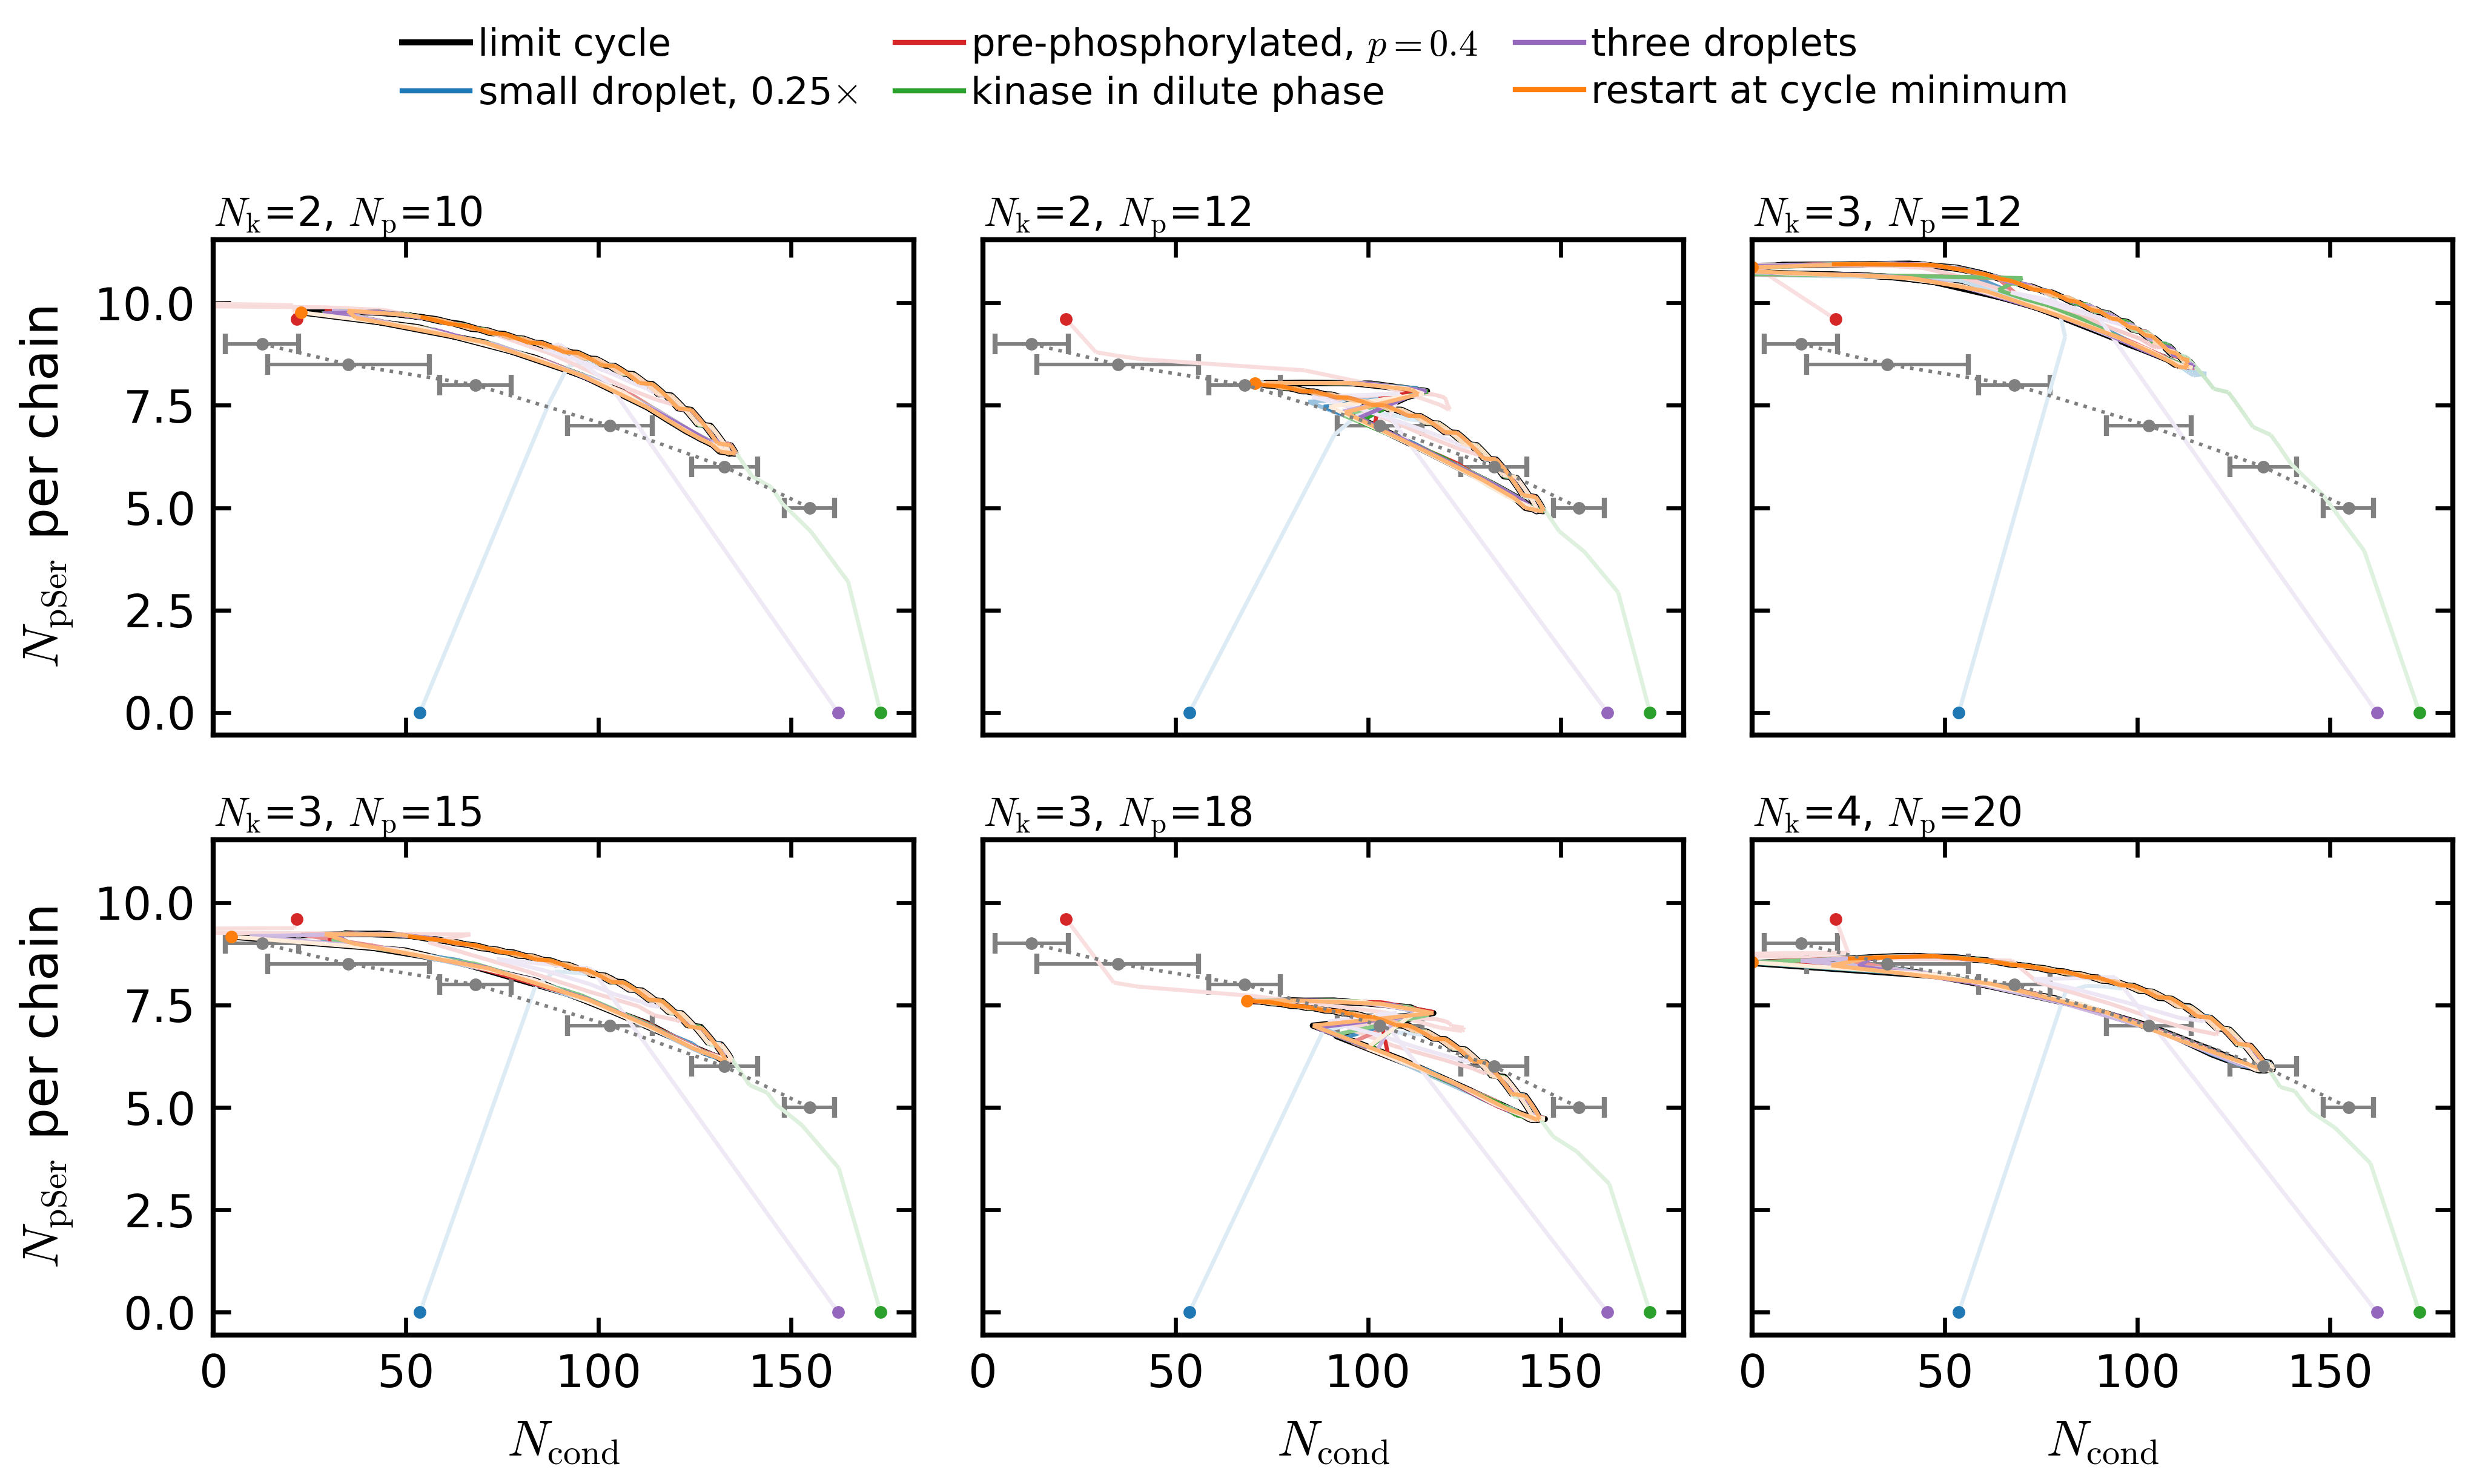

In [94]:
fig, axs = plt.subplots(2, 3, figsize=(7, 3.8), sharex=True, sharey=True)
for ax, (nk_s, np_s) in zip(axs.flat, INIT_POINTS):
    ref = load_init(nk_s, np_s, 'C_slab')
    lc = ref['t'] >= ref['t'][-1] - 2 * ref['period']          # limit cycle: last two periods
    ax.plot(ref['chains'][lc], ref['pser'][lc], color='k', lw=1.2, label='limit cycle')
    ax.errorbar(cs_eq, np_eq, xerr=dcs_eq, capsize=2, fmt='.:', color='grey', lw=0.7)   # droplets without reactions
    for label, txt, c in INIT_SHOWN:
        r = load_init(nk_s, np_s, label)
        tr = r['t'] <= N_LAPS * ref['period']
        plot_fading_trajectory(ax, r['chains'][tr], r['pser'][tr], c, linewidth=0.8, label=txt, plot_mean=False)
        ax.plot(r['chains'][0], r['pser'][0], '.', ms=3, color=c)   # start
    ax.autoscale()
    tag(ax, r'$N_\mathrm{k}$=%d, $N_\mathrm{p}$=%d' % (nk_s, np_s))
for ax in axs[1]:
    ax.set_xlabel(r'$N_{\mathrm{cond}}$')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$N_{\mathrm{pSer}}$ per chain')
axs[0, 0].set_xlim(left=0)
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(0.5, 1.0), ncols=3,
           frameon=False, fontsize=7.5, columnspacing=1.0)
plt.tight_layout()
savefig('limit_cycles_phase_field_initial_conditions')

N_k=2, N_p=10: 15/15 droplet starts oscillate; max |deviation| period 0.000%, mean pSer 0.072%, pSer amplitude 0.200%
N_k=2, N_p=12: 15/15 droplet starts oscillate; max |deviation| period 0.000%, mean pSer 0.069%, pSer amplitude 0.128%
N_k=3, N_p=12: 15/15 droplet starts oscillate; max |deviation| period 0.000%, mean pSer 0.055%, pSer amplitude 0.011%
N_k=3, N_p=15: 15/15 droplet starts oscillate; max |deviation| period 0.000%, mean pSer 0.091%, pSer amplitude 0.021%
N_k=3, N_p=18: 15/15 droplet starts oscillate; max |deviation| period 0.000%, mean pSer 0.084%, pSer amplitude 0.024%
N_k=4, N_p=20: 15/15 droplet starts oscillate; max |deviation| period 0.000%, mean pSer 0.048%, pSer amplitude 0.011%


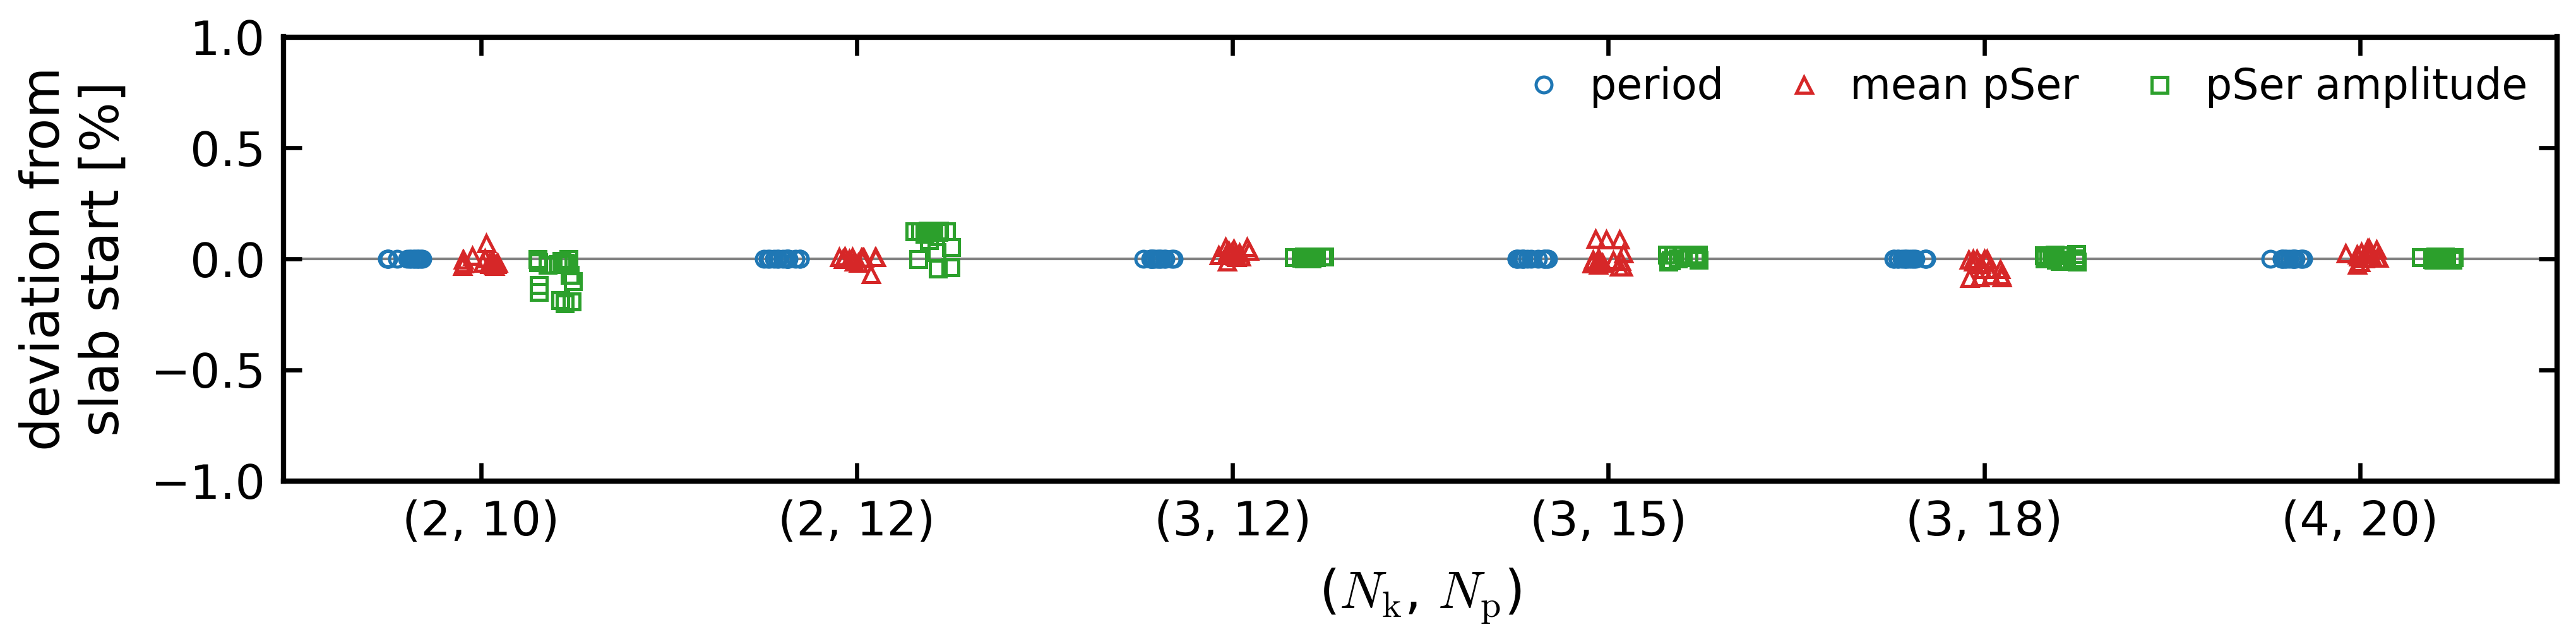

In [53]:
# deviation of period, mean pSer and pSer amplitude of every droplet start from the slab start
rng = np.random.default_rng(0)                 # horizontal jitter of the markers
QUANT = [('period', 'period', 'o', 'tab:blue', -0.2), ('pmean', 'mean pSer', '^', 'tab:red', 0.0),
         ('pamp', 'pSer amplitude', 's', 'tab:green', 0.2)]

fig, ax = plt.subplots(figsize=(7, 1.9))
for i, (nk_s, np_s) in enumerate(INIT_POINTS):
    ref = load_init(nk_s, np_s, 'C_slab')
    labels = [lab for lab in init_labels(nk_s, np_s) if lab.startswith(INIT_DROPLET) and lab != 'C_slab']
    runs = [load_init(nk_s, np_s, lab) for lab in labels]
    osc = [r for r in runs if r['cls'] == 'oscillating']
    jit = rng.uniform(-0.05, 0.05, len(osc))
    devs = {}
    for key, txt, marker, c, off in QUANT:
        devs[key] = 100 * (np.array([r[key] for r in osc]) / ref[key] - 1)
        ax.plot(i + off + jit, devs[key], marker, ms=3, mfc='none', mec=c, mew=0.6, label=txt if i == 0 else None)
    print(f"N_k={nk_s}, N_p={np_s}: {len(osc)}/{len(runs)} droplet starts oscillate; max |deviation| "
          + ', '.join(f"{txt} {np.abs(devs[key]).max():.3f}%" for key, txt, *_ in QUANT))
ax.axhline(0, color='grey', lw=0.5, zorder=0)
ax.set_xticks(range(len(INIT_POINTS)), ['(%d, %d)' % pt for pt in INIT_POINTS])
ax.set_xlabel(r'($N_\mathrm{k}$, $N_\mathrm{p}$)')
ax.set_ylabel('deviation from\nslab start [%]')
ax.set_ylim(-1, 1)
ax.legend(loc='upper right', ncols=3, frameon=False)
plt.tight_layout()
savefig('limit_cycles_phase_field_initial_conditions_deviation')

Cross-correlations

In [23]:
# total cross-correlation pSer - cluster size (lags in us)
lags_md, corr_md = cross_correlation(signal.detrend(M['pser']), signal.detrend(M['chains']))
lags_md = lags_md * dt_md

lags_pf, corr_pf = cross_correlation(signal.detrend(D['pser'][i_lc:]), signal.detrend(D['chains'][i_lc:]))
lags_pf = lags_pf * dt_mod

# sliding-window cross-correlation of the MD run, and period from the distance of the side peaks
window = 400
step = 20
C_sl, lags_slide, times = sliding_window_correlation(M['pser'], M['chains'], window, step, dt=dt_md)
times = times + M['t'][0]      # window centres in us of the run

peaks_dist = []
for i in range(len(C_sl)):
    tmp1, _ = signal.find_peaks(C_sl[i, :window], prominence=0.1)
    tmp2, _ = signal.find_peaks(C_sl[i, window:], prominence=0.1)
    if len(tmp1) and len(tmp2):
        peaks_dist.append(lags_slide[tmp2[0] + window] - lags_slide[tmp1[-1]])
    else:
        peaks_dist.append(np.nan)
peaks_dist = np.asarray(peaks_dist)

Oscillation period of the oscillating MD systems: sliding-window cross-correlation and Fourier spectrum

For every oscillating MD system (one replica each):
- left: period in time from the sliding-window cross-correlation pSer - cluster size (distance of the side peaks around lag 0, as above)
- right: full-trajectory spectrum $|\mathrm{FFT}|$ of the total cross-correlation (Hann window, zero padding) against the period,
  with the histogram of the sliding-window periods; grey: fewer than 3 cycles in the run (not resolved)

The spectral peak is refined with a parabola through the 3 points around the maximum; its resolution is half a frequency bin,
$\pm 1/(2 T_{run})$, converted to period. Dashed line: spectral peak; dotted grey line: period of the phase-field cell, if present.

In [24]:
# MD runs of the oscillating systems: replica and thermalization from MD_RUNS (rows of 0.04 us)
OSC_SYSTEMS = [(2, 10), (2, 12), (3, 12), (3, 15), (4, 14), (4, 20)]
WINDOW, STEP = 400, 20     # sliding window (16 us), shifted by 20 frames, as above
T_MAX = 20                 # us, upper limit of the period axis
MIN_CYCLES = 3             # periods with fewer cycles than this in the run are not resolved


def sliding_period(pser, chains, dt, window=WINDOW, step=STEP, prominence=0.1):
    '''Period in every sliding window: distance of the closest cross-correlation peaks at negative and positive lag.'''
    C, lags, times = sliding_window_correlation(pser, chains, window, step, dt=dt)
    period = []
    for row in C:
        left, _ = signal.find_peaks(row[:window], prominence=prominence)
        right, _ = signal.find_peaks(row[window:], prominence=prominence)
        period.append(lags[right[0] + window] - lags[left[-1]] if len(left) and len(right) else np.nan)
    return times, np.asarray(period)


def cross_spectrum(pser, chains, dt, pad=64):
    '''|FFT| of the full cross-correlation of the detrended signals (Hann window, zero padding):
    the cross-power spectrum. Returns frequencies [1/us] and power.'''
    _, corr = cross_correlation(signal.detrend(pser), signal.detrend(chains))
    c = corr * signal.windows.hann(len(corr))
    n = pad * len(c)
    return np.fft.rfftfreq(n, dt), np.abs(np.fft.rfft(c, n))


def spectral_peak(freqs, power, fmin, fmax=2.0):
    '''Frequency of the highest peak in (fmin, fmax), refined by a parabola through the 3 points around it.'''
    ok = (freqs > fmin) & (freqs < fmax)
    i = np.flatnonzero(ok)[np.argmax(power[ok])]
    a, b, c = np.log(power[i - 1:i + 2])
    return freqs[i] + 0.5 * (a - c) / (a - 2 * b + c) * (freqs[1] - freqs[0])


osc_period = {}
for nk_s, np_s in OSC_SYSTEMS:
    r = MD_RUNS[(nk_s, np_s)]
    t_s, cs_s, n_p_s = read_chains_in_condensate(path_drop_fr_an, 200, nk_s, np_s, 'ness', r['ss'], therm=r['therm'])
    t_s, pser_s = t_s / 1e8, n_p_s / 200                     # us, pSer per chain
    dt_s = t_s[1] - t_s[0]
    T_run = len(t_s) * dt_s

    freqs, power = cross_spectrum(pser_s, cs_s, dt_s)
    f0 = spectral_peak(freqs, power, MIN_CYCLES / T_run)
    tw, Tw = sliding_period(pser_s, cs_s, dt_s)
    model_file = cell_file(nk_s, np_s)
    osc_period[(nk_s, np_s)] = dict(
        ss=r['ss'], T_run=T_run, freqs=freqs, power=power / power[freqs > MIN_CYCLES / T_run].max(),
        T_fft=1 / f0, dT_fft=0.5 / (f0**2 * T_run), cycles=T_run * f0,
        t_slide=tw + t_s[0], T_slide=Tw,
        T_model=float(np.load(model_file)['period']) if os.path.exists(model_file) else np.nan)

print(f"{'N_k,N_p':>8} {'rep':>3} {'run [us]':>8} {'cycles':>6} {'T_FFT [us]':>12} {'T_sliding median (IQR)':>24} {'T_model':>8}")
for (nk_s, np_s), o in osc_period.items():
    Tw = o['T_slide'][np.isfinite(o['T_slide'])]
    print(f"{nk_s:>4},{np_s:<3} {o['ss']:>3} {o['T_run']:8.1f} {o['cycles']:6.1f} {o['T_fft']:6.2f} ± {o['dT_fft']:.2f} "
          f"{np.median(Tw):10.2f} ({np.percentile(Tw, 25):.2f}-{np.percentile(Tw, 75):.2f}) {o['T_model']:8.2f}")

 N_k,N_p rep run [us] cycles   T_FFT [us]   T_sliding median (IQR)  T_model
   2,10    3     59.0    8.4   7.00 ± 0.41       8.02 (7.68-8.80)     6.64
   2,12    2     49.0    5.2   9.43 ± 0.91       8.00 (5.87-9.25)    10.42
   3,12    1     59.0    6.2   9.58 ± 0.78       6.84 (4.93-7.56)     3.08
   3,15    3     39.0    8.4   4.63 ± 0.27       6.60 (5.08-8.12)     5.07
   4,14    1     40.0    6.9   5.76 ± 0.41       5.34 (3.53-5.84)      nan
   4,20    1     58.0    7.0   8.31 ± 0.59       5.68 (5.04-6.80)     4.57


In [25]:
osc_period[(3,15)]

{'ss': 3,
 'T_run': 39.000000000000036,
 'freqs': array([0.00000000e+00, 2.00423294e-04, 4.00846588e-04, ...,
        1.24995992e+01, 1.24997996e+01, 1.25000000e+01]),
 'power': array([0.01867824, 0.01874111, 0.01892867, ..., 0.00025956, 0.00025963,
        0.00025966]),
 'T_fft': 4.625558945253838,
 'dT_fft': 0.27430507123099723,
 'cycles': 8.431413470585406,
 't_slide': array([ 9. ,  9.8, 10.6, 11.4, 12.2, 13. , 13.8, 14.6, 15.4, 16.2, 17. ,
        17.8, 18.6, 19.4, 20.2, 21. , 21.8, 22.6, 23.4, 24.2, 25. , 25.8,
        26.6, 27.4, 28.2, 29. , 29.8, 30.6, 31.4]),
 'T_slide': array([ 6.92,  6.32,  5.36,  5.08,  4.28,  4.4 ,  4.64,  4.52,  3.76,
         8.32,  8.68,  8.76, 12.24,  8.64,  8.32,  8.04,  8.12,  7.6 ,
         9.2 ,  6.72,  8.  ,  6.84,  6.6 ,  5.76,  5.76,  5.48,  5.2 ,
         5.08,  5.  ]),
 'T_model': 5.065084752166463}

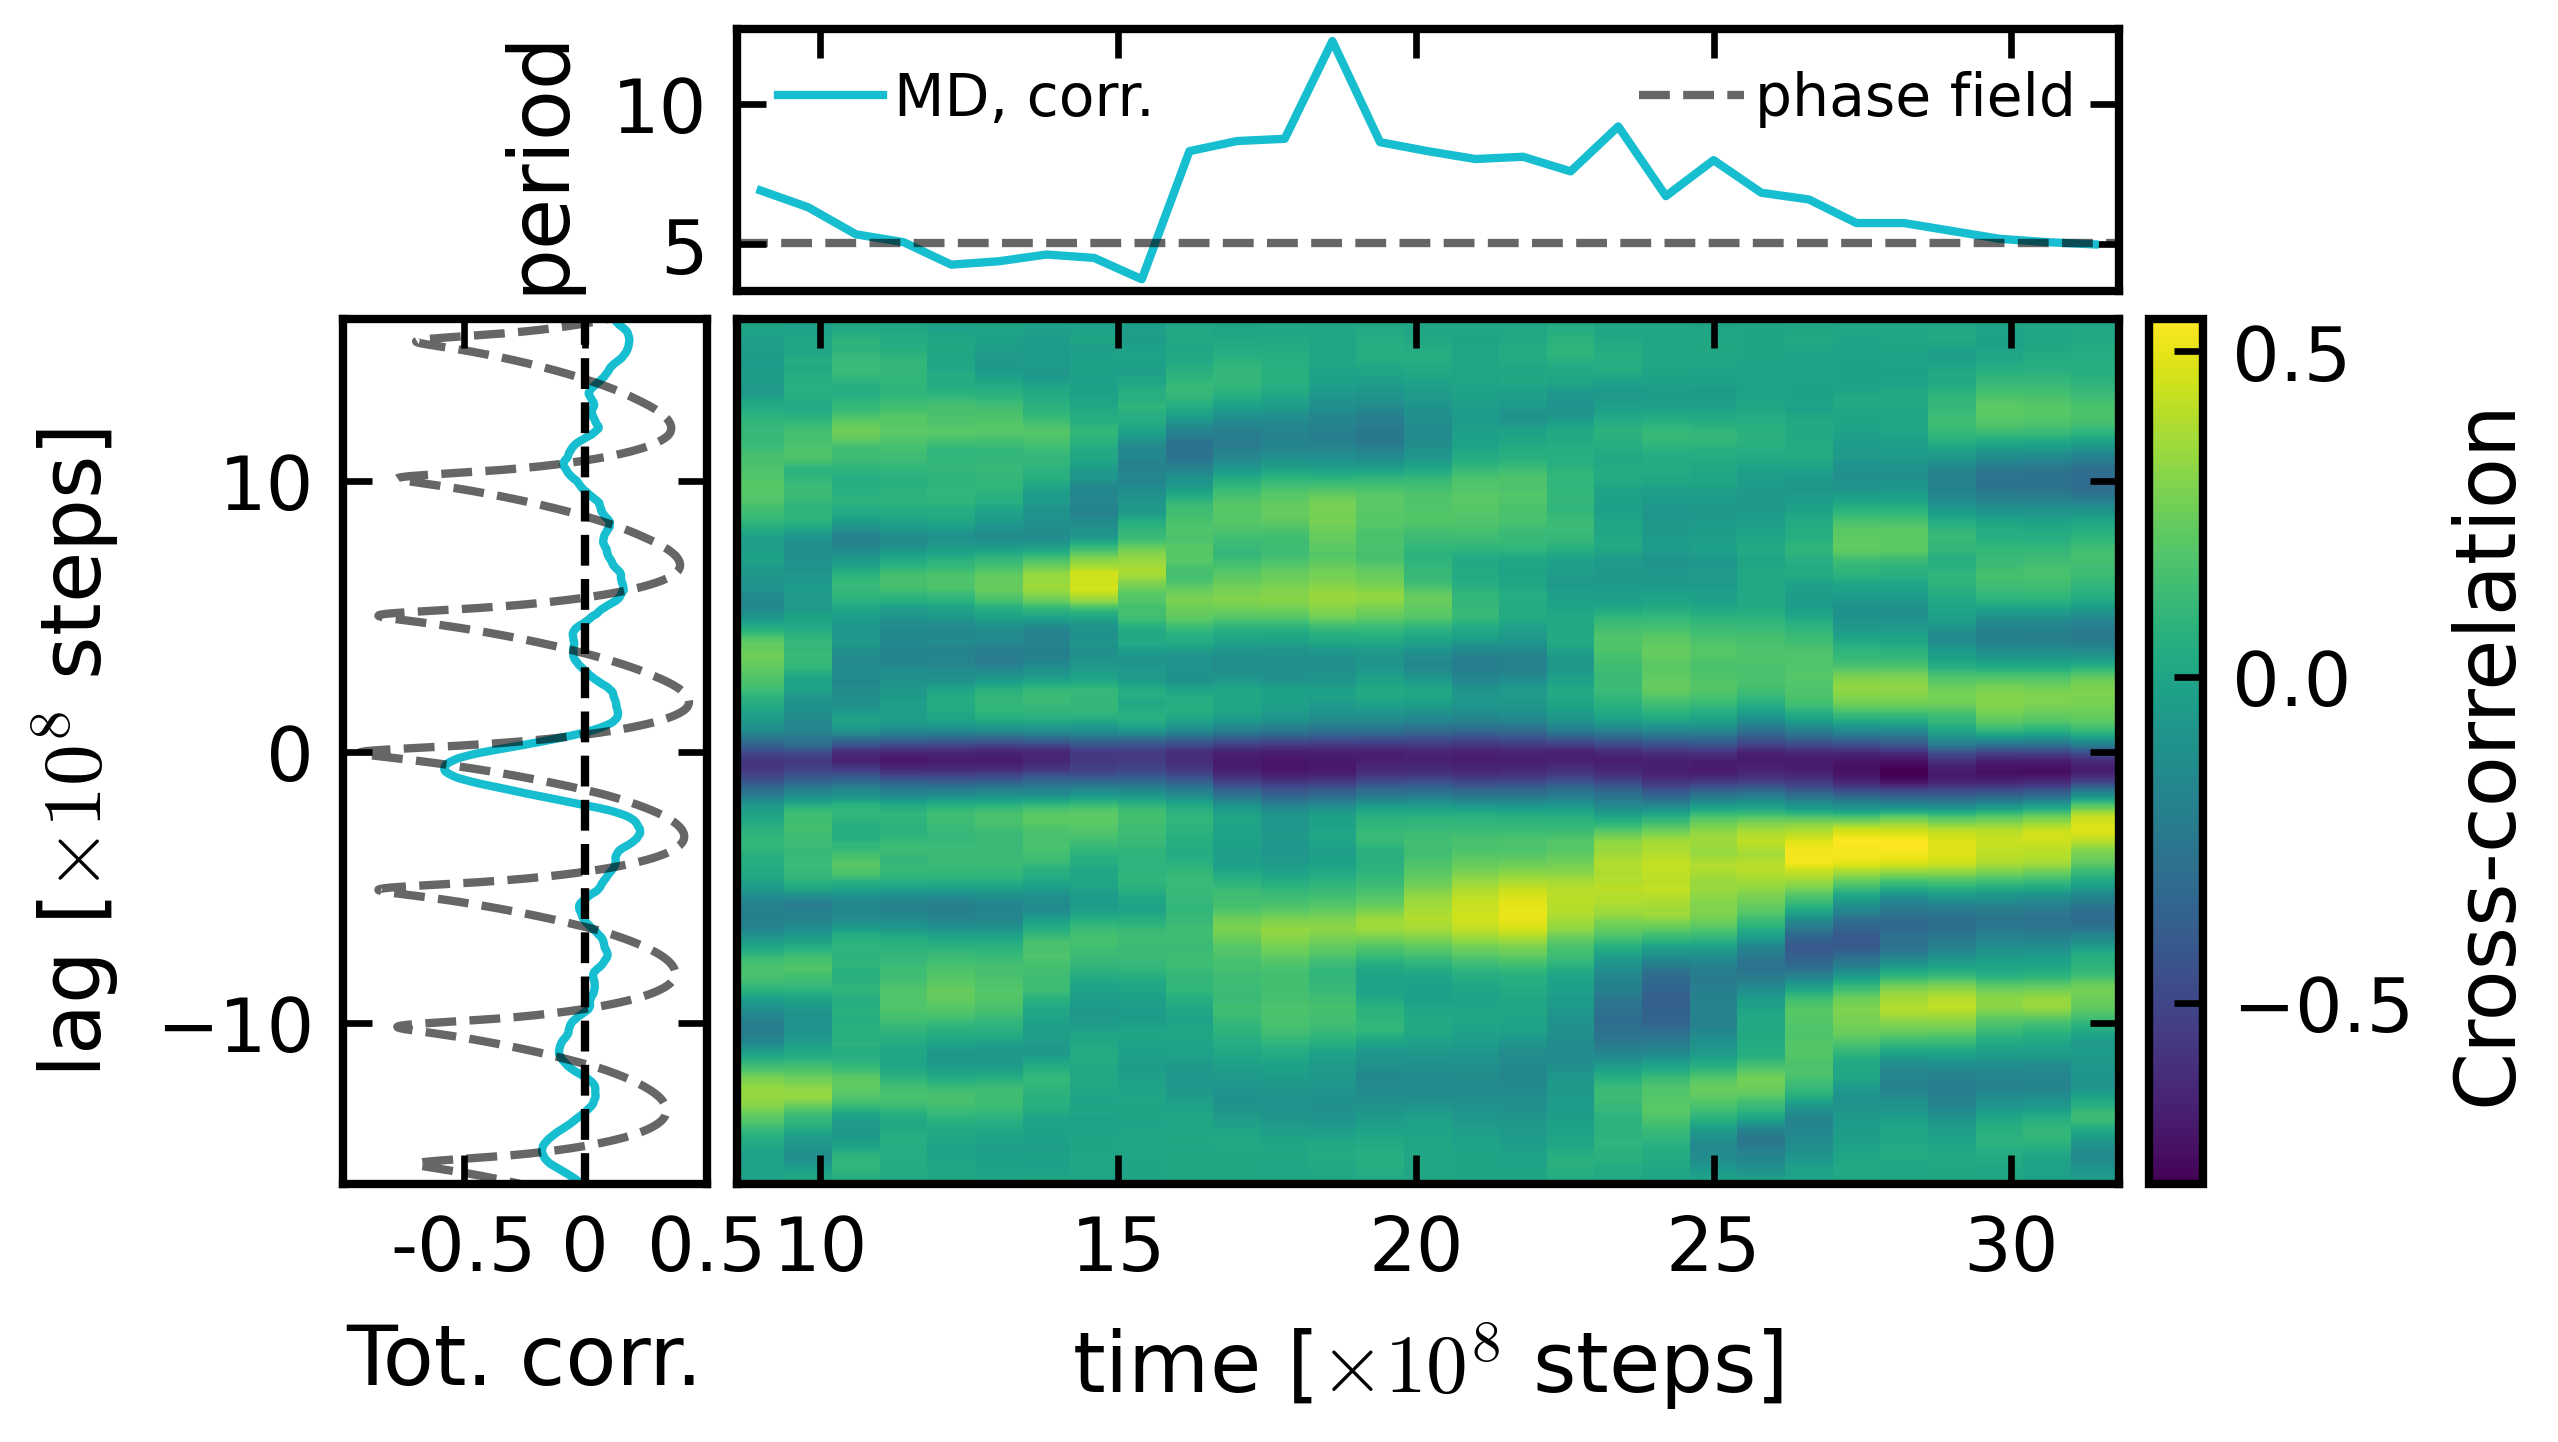

In [26]:
fig = plt.figure(figsize=(4., 2.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 3.8, 0.15], height_ratios=[1, 3.3], wspace=0.05, hspace=0.05)

# sliding-window cross-correlation
ax = fig.add_subplot(gs[1, 1])
pcm = ax.pcolormesh(times, lags_slide, C_sl.T, shading='auto')
ax.set_xlabel(r'time [$\times 10^8$ steps]')
ax.set_ylim(lags_slide.min(), lags_slide.max())
ax.tick_params(axis='y', left=False, labelleft=False)

# total cross-correlation
ax_total = fig.add_subplot(gs[1, 0], sharey=ax)
ax_total.plot(corr_md, lags_md, color='tab:cyan', label='MD')
ax_total.plot(corr_pf, lags_pf, '--', c='k', alpha=0.6, label='phase field')
ax_total.axvline(0, linestyle='--', color='k', linewidth=1)
ax_total.set_ylabel(r'lag [$\times 10^8$ steps]')
ax_total.set_xlabel('Tot. corr.')
ax_total.set_xticks([-0.5, 0, 0.5],[-0.5, 0, 0.5])
ax_total.set_ylim(ax.get_ylim())

# colorbar
cbar = fig.colorbar(pcm, cax=fig.add_subplot(gs[1, 2]))
cbar.set_label('Cross-correlation')

# oscillation period
ax_dt = fig.add_subplot(gs[0, 1], sharex=ax)
ax_dt.plot(times, peaks_dist, color='tab:cyan', label='MD, corr.' + ' ' * 23)      # padding keeps the legend columns apart
#ax_dt.axhline(osc_period[(3,15)]['T_fft'], color='k', lw=0.6, ls=':', label=f"MD, FFT")
ax_dt.axhline(D['period'], color='k', ls='--', alpha=0.6, label='phase field')
ax_dt.set_ylabel('period')
ax_dt.tick_params(axis='x', bottom=False, labelbottom=False)
ax_dt.legend(loc='upper left', framealpha=0, ncols=3, fontsize=7)
#ax_dt.set_ylim(3.5, 14)

savefig(f'cross_correlation_sliding_model_compare_{sys_tag}', dpi=300)

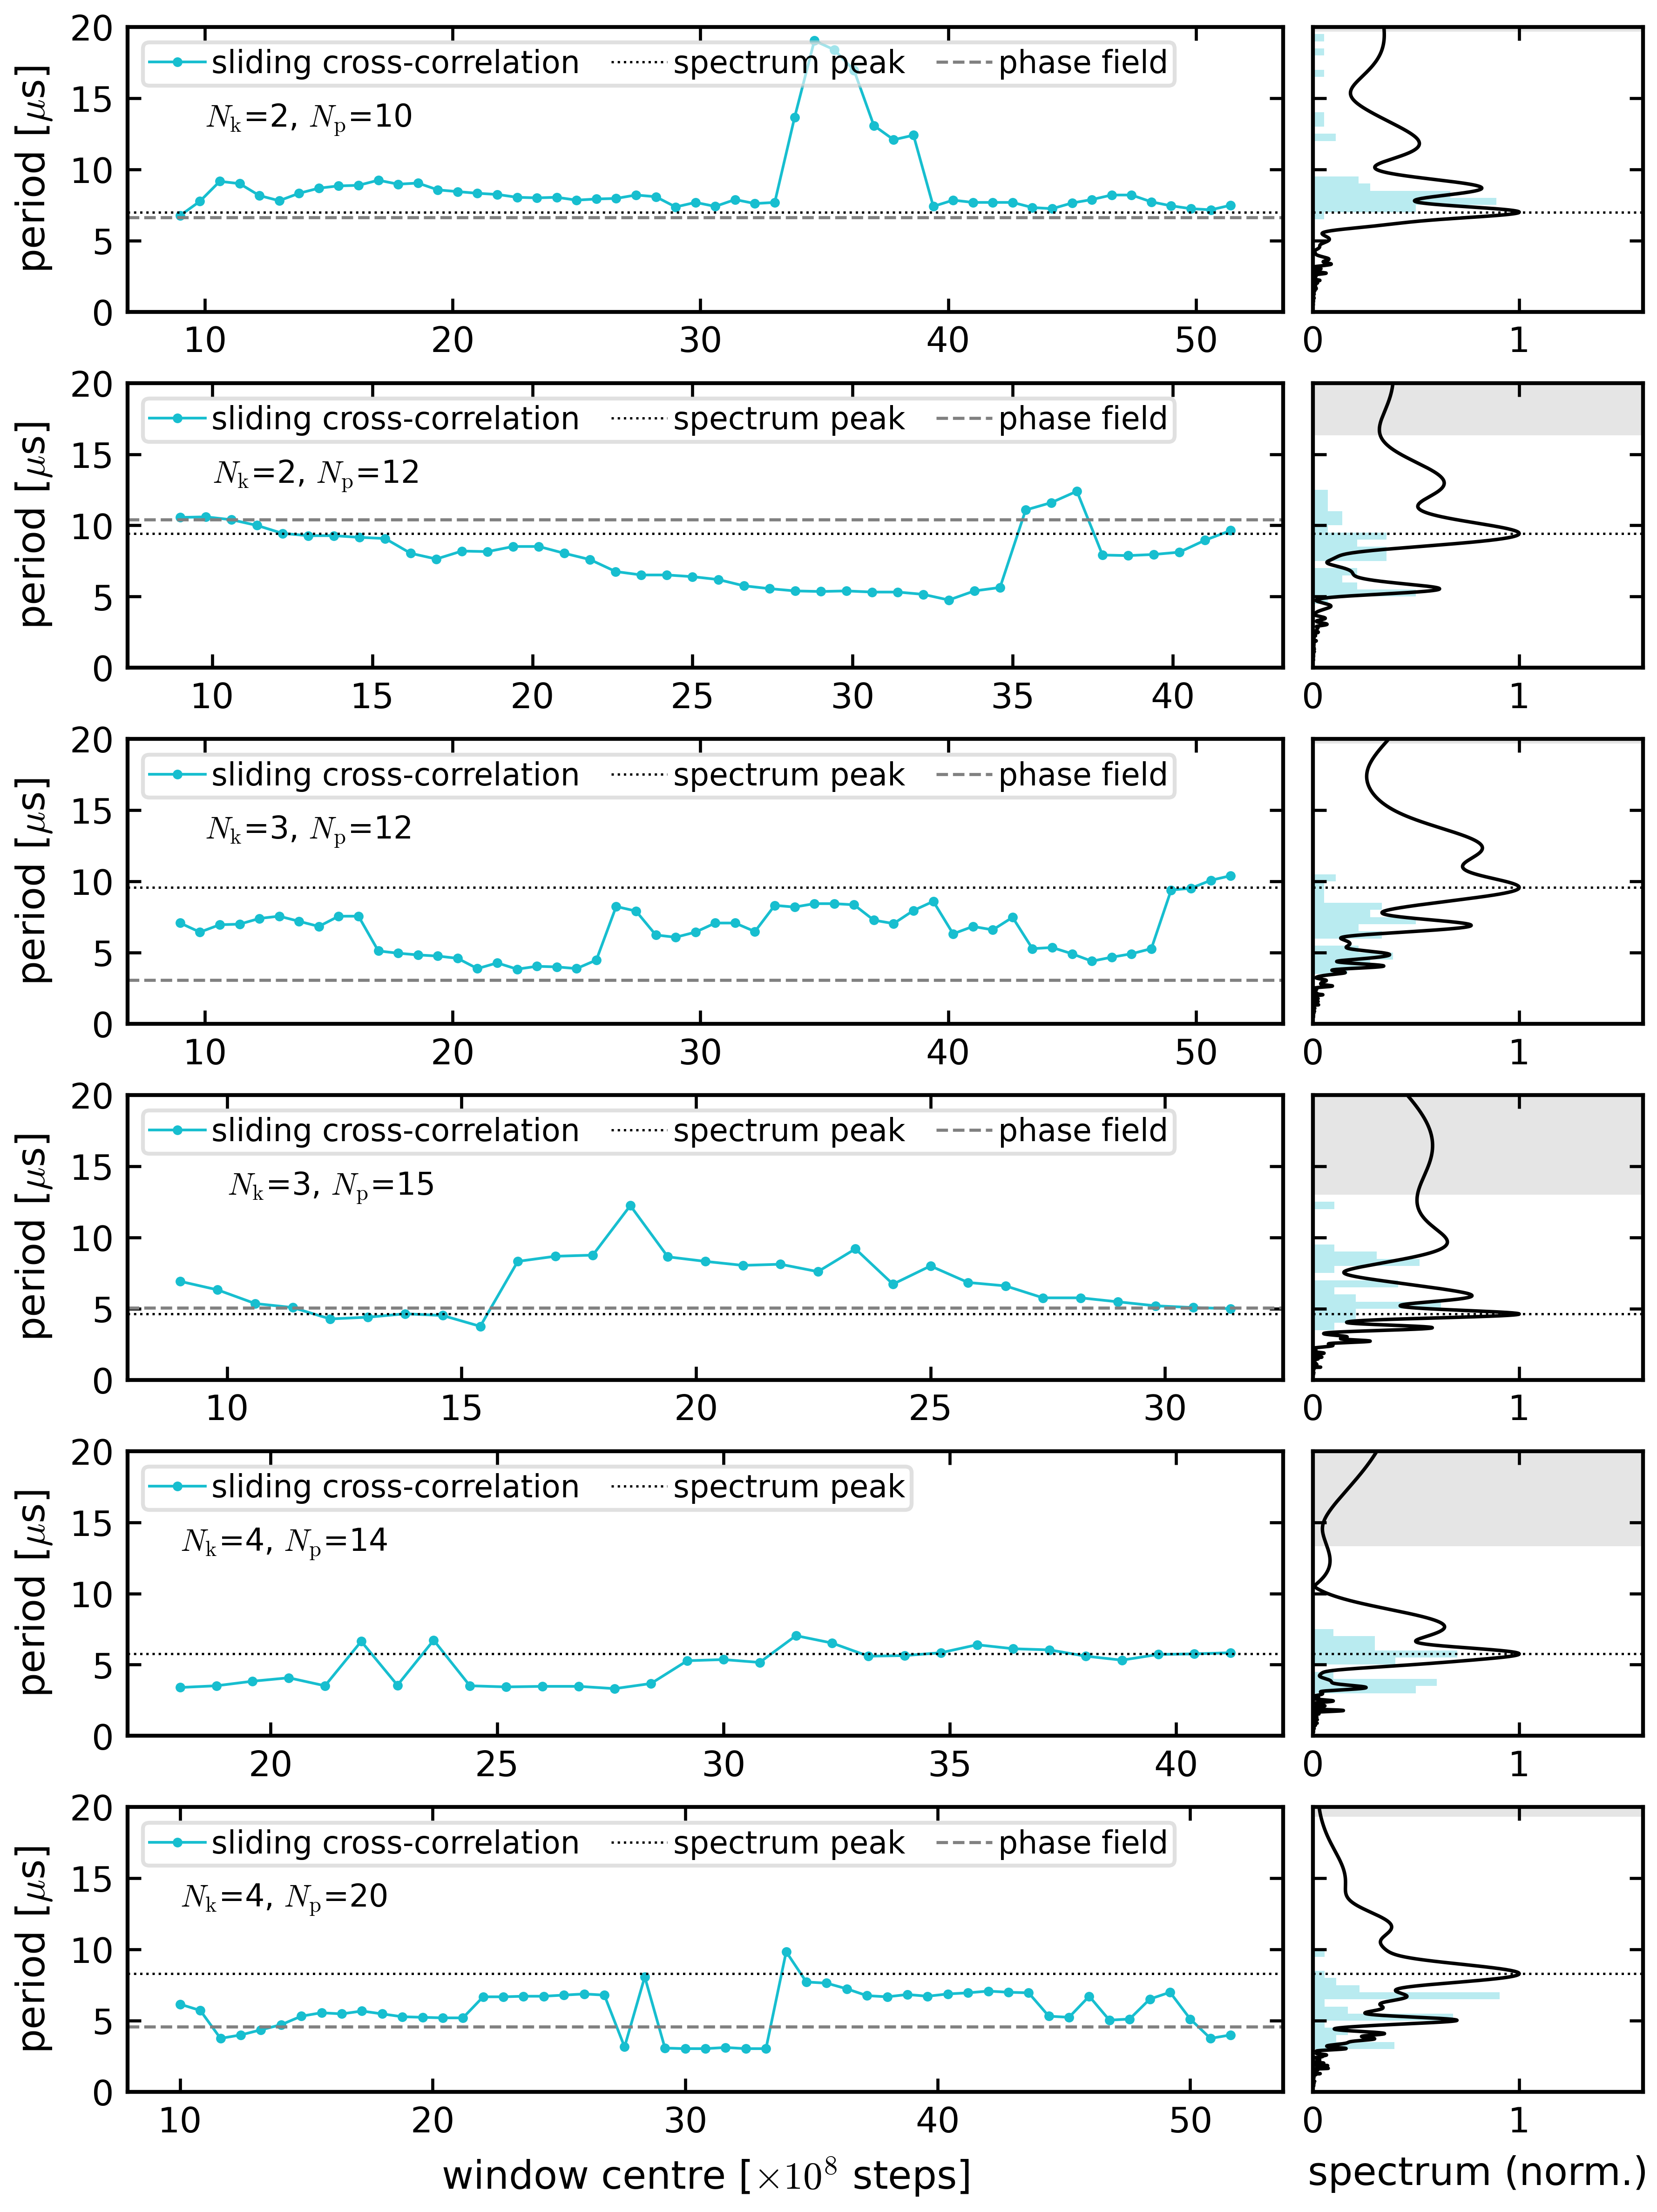

In [64]:
fig = plt.figure(figsize=(7, 1.6 * len(OSC_SYSTEMS)))
gs = fig.add_gridspec(len(OSC_SYSTEMS), 2, width_ratios=[3.5, 1], wspace=0.04, hspace=0.25)
bins = np.arange(0, T_MAX + 0.5, 0.5)

for row, ((nk_s, np_s), o) in enumerate(osc_period.items()):
    # period in time from the sliding-window cross-correlation
    ax = fig.add_subplot(gs[row, 0])
    ax.plot(o['t_slide'], o['T_slide'], '.-', ms=3, lw=0.7, color='tab:cyan', label='sliding cross-correlation')
    ax.axhline(o['T_fft'], color='k', lw=0.6, ls=':', label=f"spectrum peak")
    if np.isfinite(o['T_model']):
        ax.axhline(o['T_model'], color='grey', lw=0.8, ls='--', label=f"phase field")
    ax.set_ylim(0, T_MAX)
    ax.set_ylabel(r'period [$\mu$s]')
    if np_s==14:
        ax.text(18,13, r'$N_\mathrm{k}$=%d, $N_\mathrm{p}$=%d' % (nk_s, np_s), fontsize=8)
    else:
        ax.text(10,13, r'$N_\mathrm{k}$=%d, $N_\mathrm{p}$=%d' % (nk_s, np_s), fontsize=8)
    ax.legend(fontsize=8, loc='upper left', framealpha=0.6, ncols=3)
    if row == len(OSC_SYSTEMS) - 1:
        ax.set_xlabel(r'window centre [$\times 10^8$ steps]')

    # full-trajectory spectrum vs period, and histogram of the sliding-window periods
    axs = fig.add_subplot(gs[row, 1], sharey=ax)
    show = o['freqs'] > 1 / T_MAX
    axs.plot(o['power'][show], 1 / o['freqs'][show], color='k', lw=0.9)
    Tw = o['T_slide'][np.isfinite(o['T_slide'])]
    axs.hist(Tw, bins=bins, weights=np.full(len(Tw), 3 / len(Tw)), orientation='horizontal', alpha=0.3, color='tab:cyan')
    axs.axhspan(o['T_run'] / MIN_CYCLES, T_MAX, color='grey', alpha=0.2, lw=0)
    axs.axhline(o['T_fft'], color='k', lw=0.6, ls=':')
    axs.set_xlim(0, 1.6)
    axs.tick_params(axis='y', labelleft=False)
    if row == len(OSC_SYSTEMS) - 1:
        axs.set_xlabel('spectrum (norm.)')

savefig('period_sliding_vs_spectrum_MD_oscillating', dpi=300)

Density profiles in phase field model

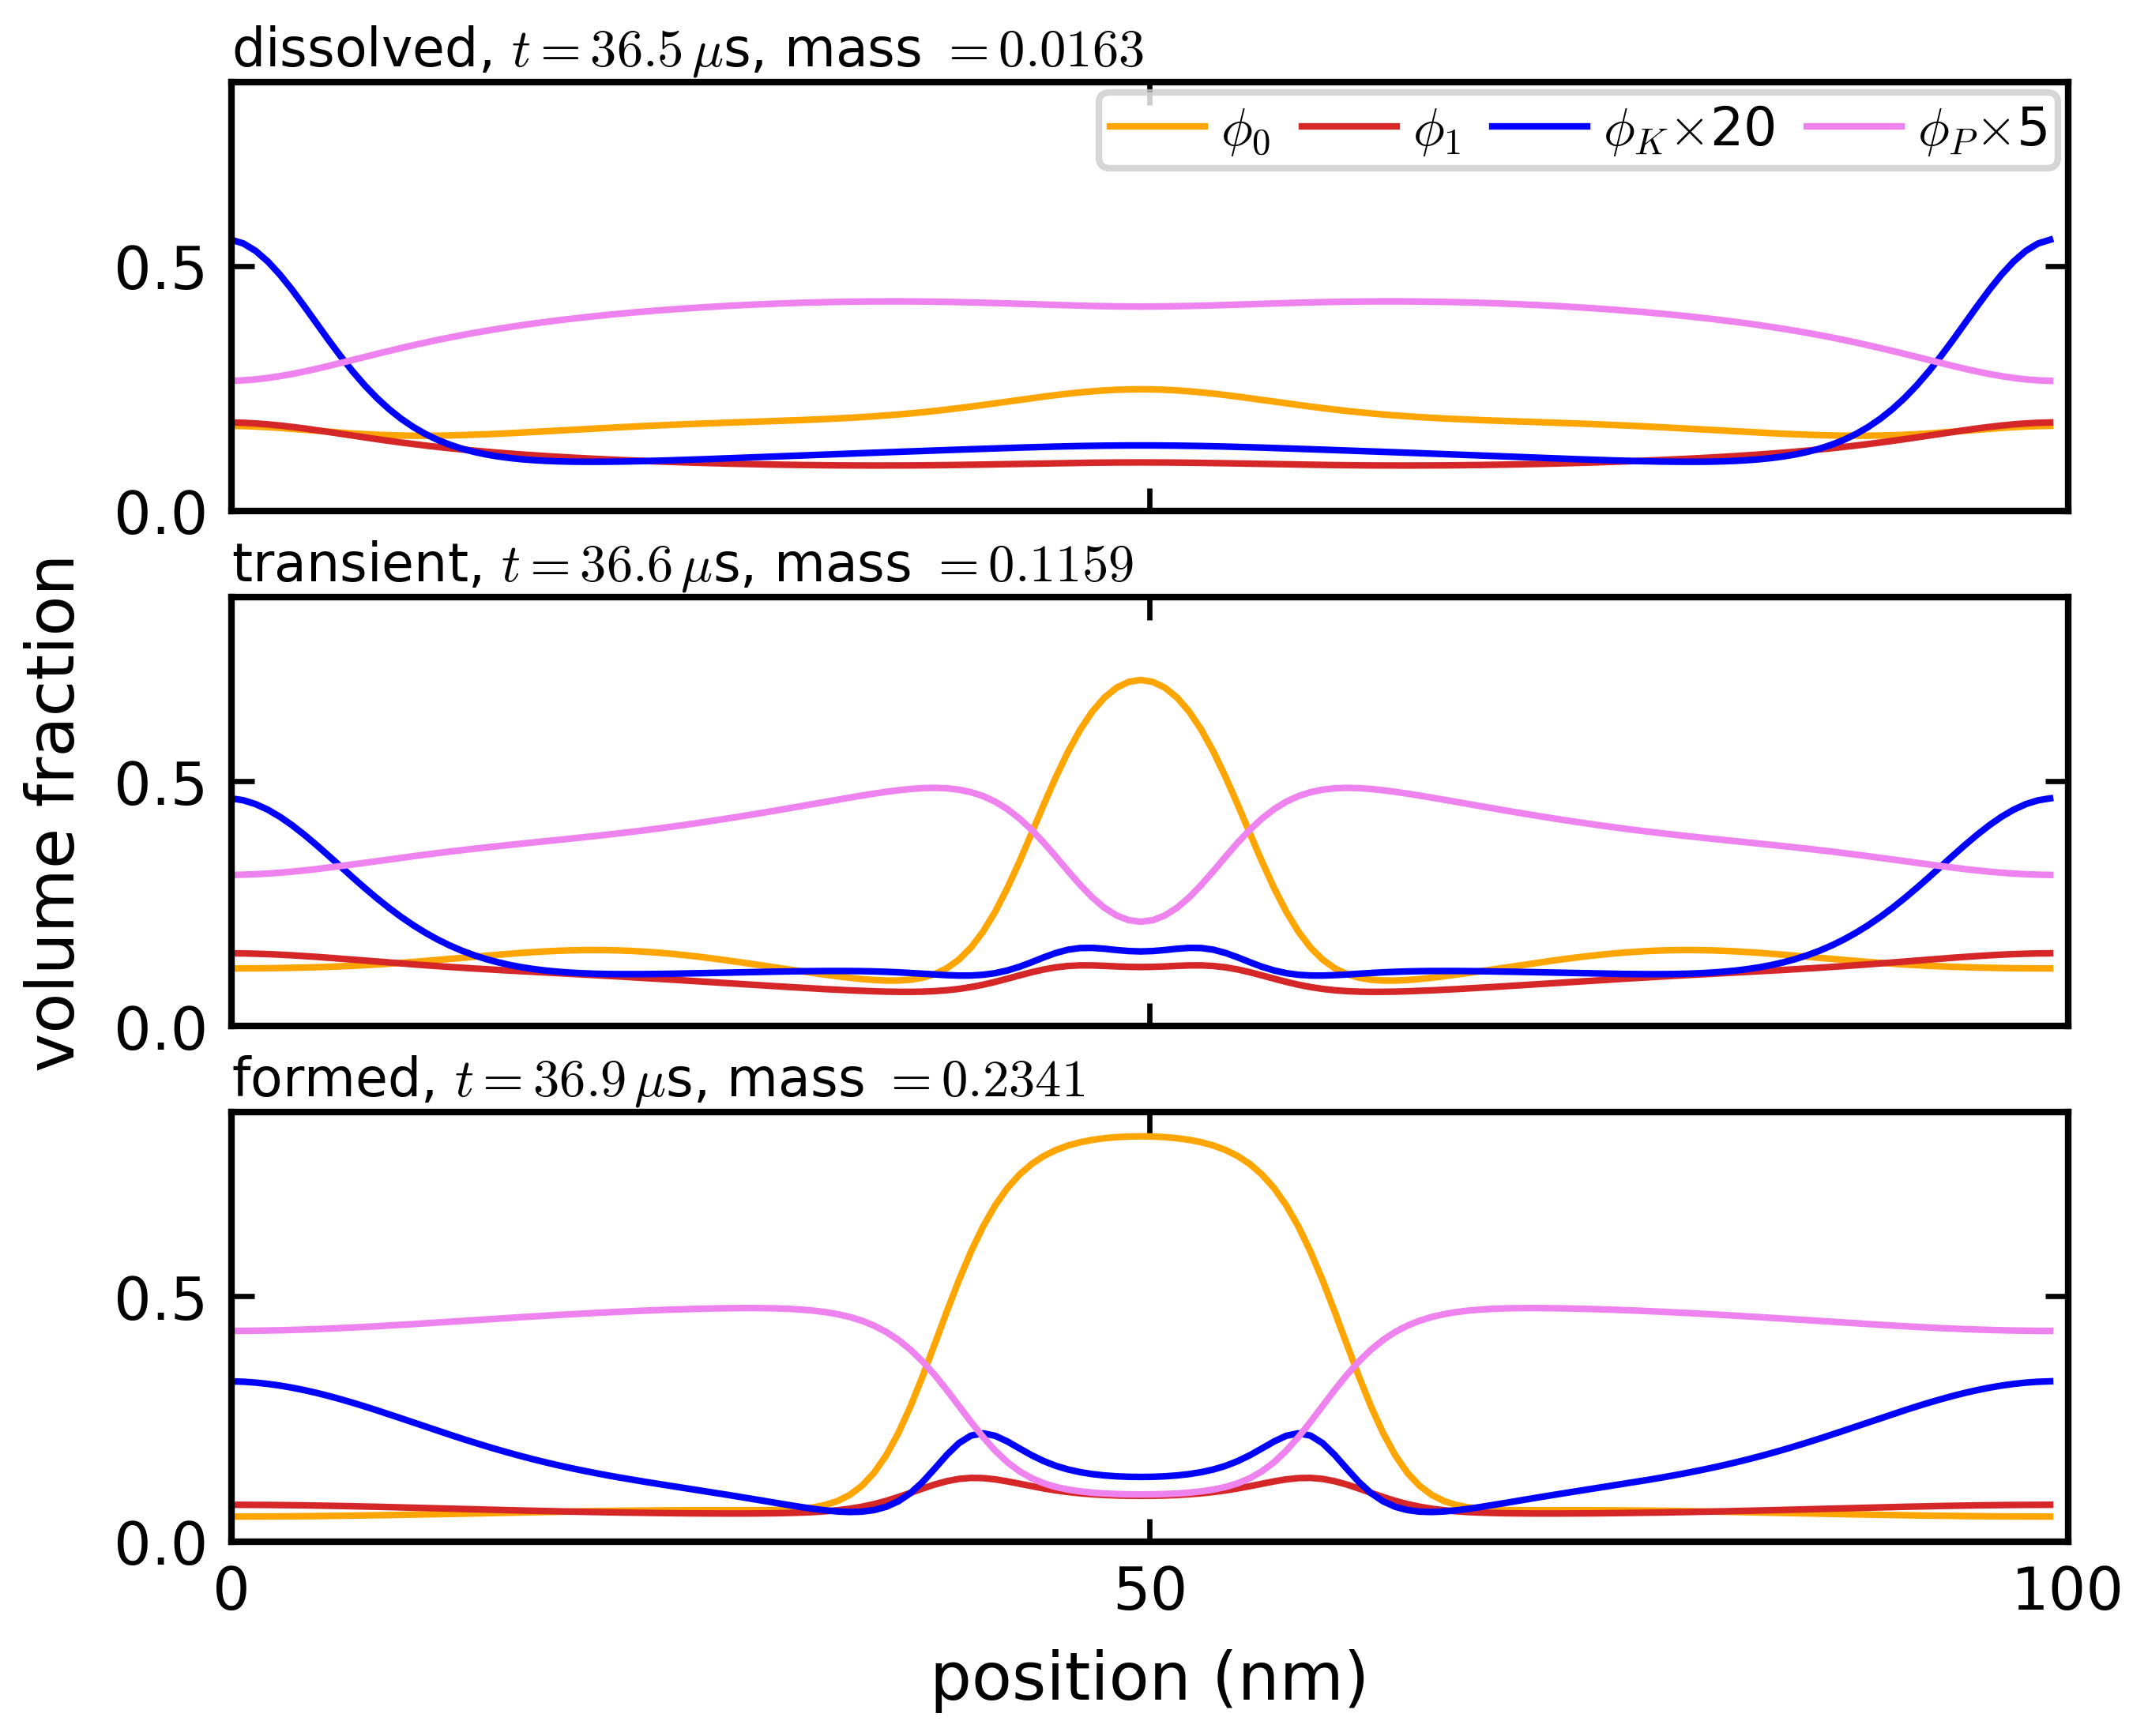

In [42]:
FIELDC = {'phi0': 'orange', 'phi1': 'tab:red', 'phiK': 'blue', 'phiP': 'violet'}
SCALE = {'phiK': 20, 'phiP': 5}             # enzymes magnified to be visible
idx = cycle_times(D, i_lc)
names = ['dissolved', 'transient', 'formed']
x = np.linspace(0, D['Lnm'], D['phi0'].shape[1], endpoint=False)
ymax = max((D[f][list(idx)] * SCALE.get(f, 1)).max() for f in FIELDC) * 1.06

fig, ax = plt.subplots(3, 1, figsize=(5, 4))
for k, (i, nm) in enumerate(zip(idx, names)):
    for fld in ('phi0', 'phi1', 'phiK', 'phiP'):
        s = SCALE.get(fld, 1)
        lab = FIELDL[fld] + (r'$\times$%d' % s if s != 1 else '')
        ax[k].plot(x, D[fld][i] * s, color=FIELDC[fld], label=lab)
    ax[k].set_ylim(0, ymax)
    ax[k].set_xlim(0, 100)
    ax[k].set_xticks([0, 50, 100])
    tag(ax[k], r'%s, $t=%.1f\,\mu$s, mass $=%.4f$' % (nm, D['t'][i], D['mass'][i]))
    if k == 1:
        ax[k].set_ylabel('volume fraction')
    if k < 2:
        ax[k].set_xticklabels([])
    else:
        ax[k].set_xlabel('position (nm)')
ax[0].legend(loc='upper right', ncol=4, borderaxespad=0.2,
             labelspacing=0.2, columnspacing=0.6, handletextpad=0.3)
savefig(f'density_profiles_phase_field_{sys_tag}')

Phase diagram

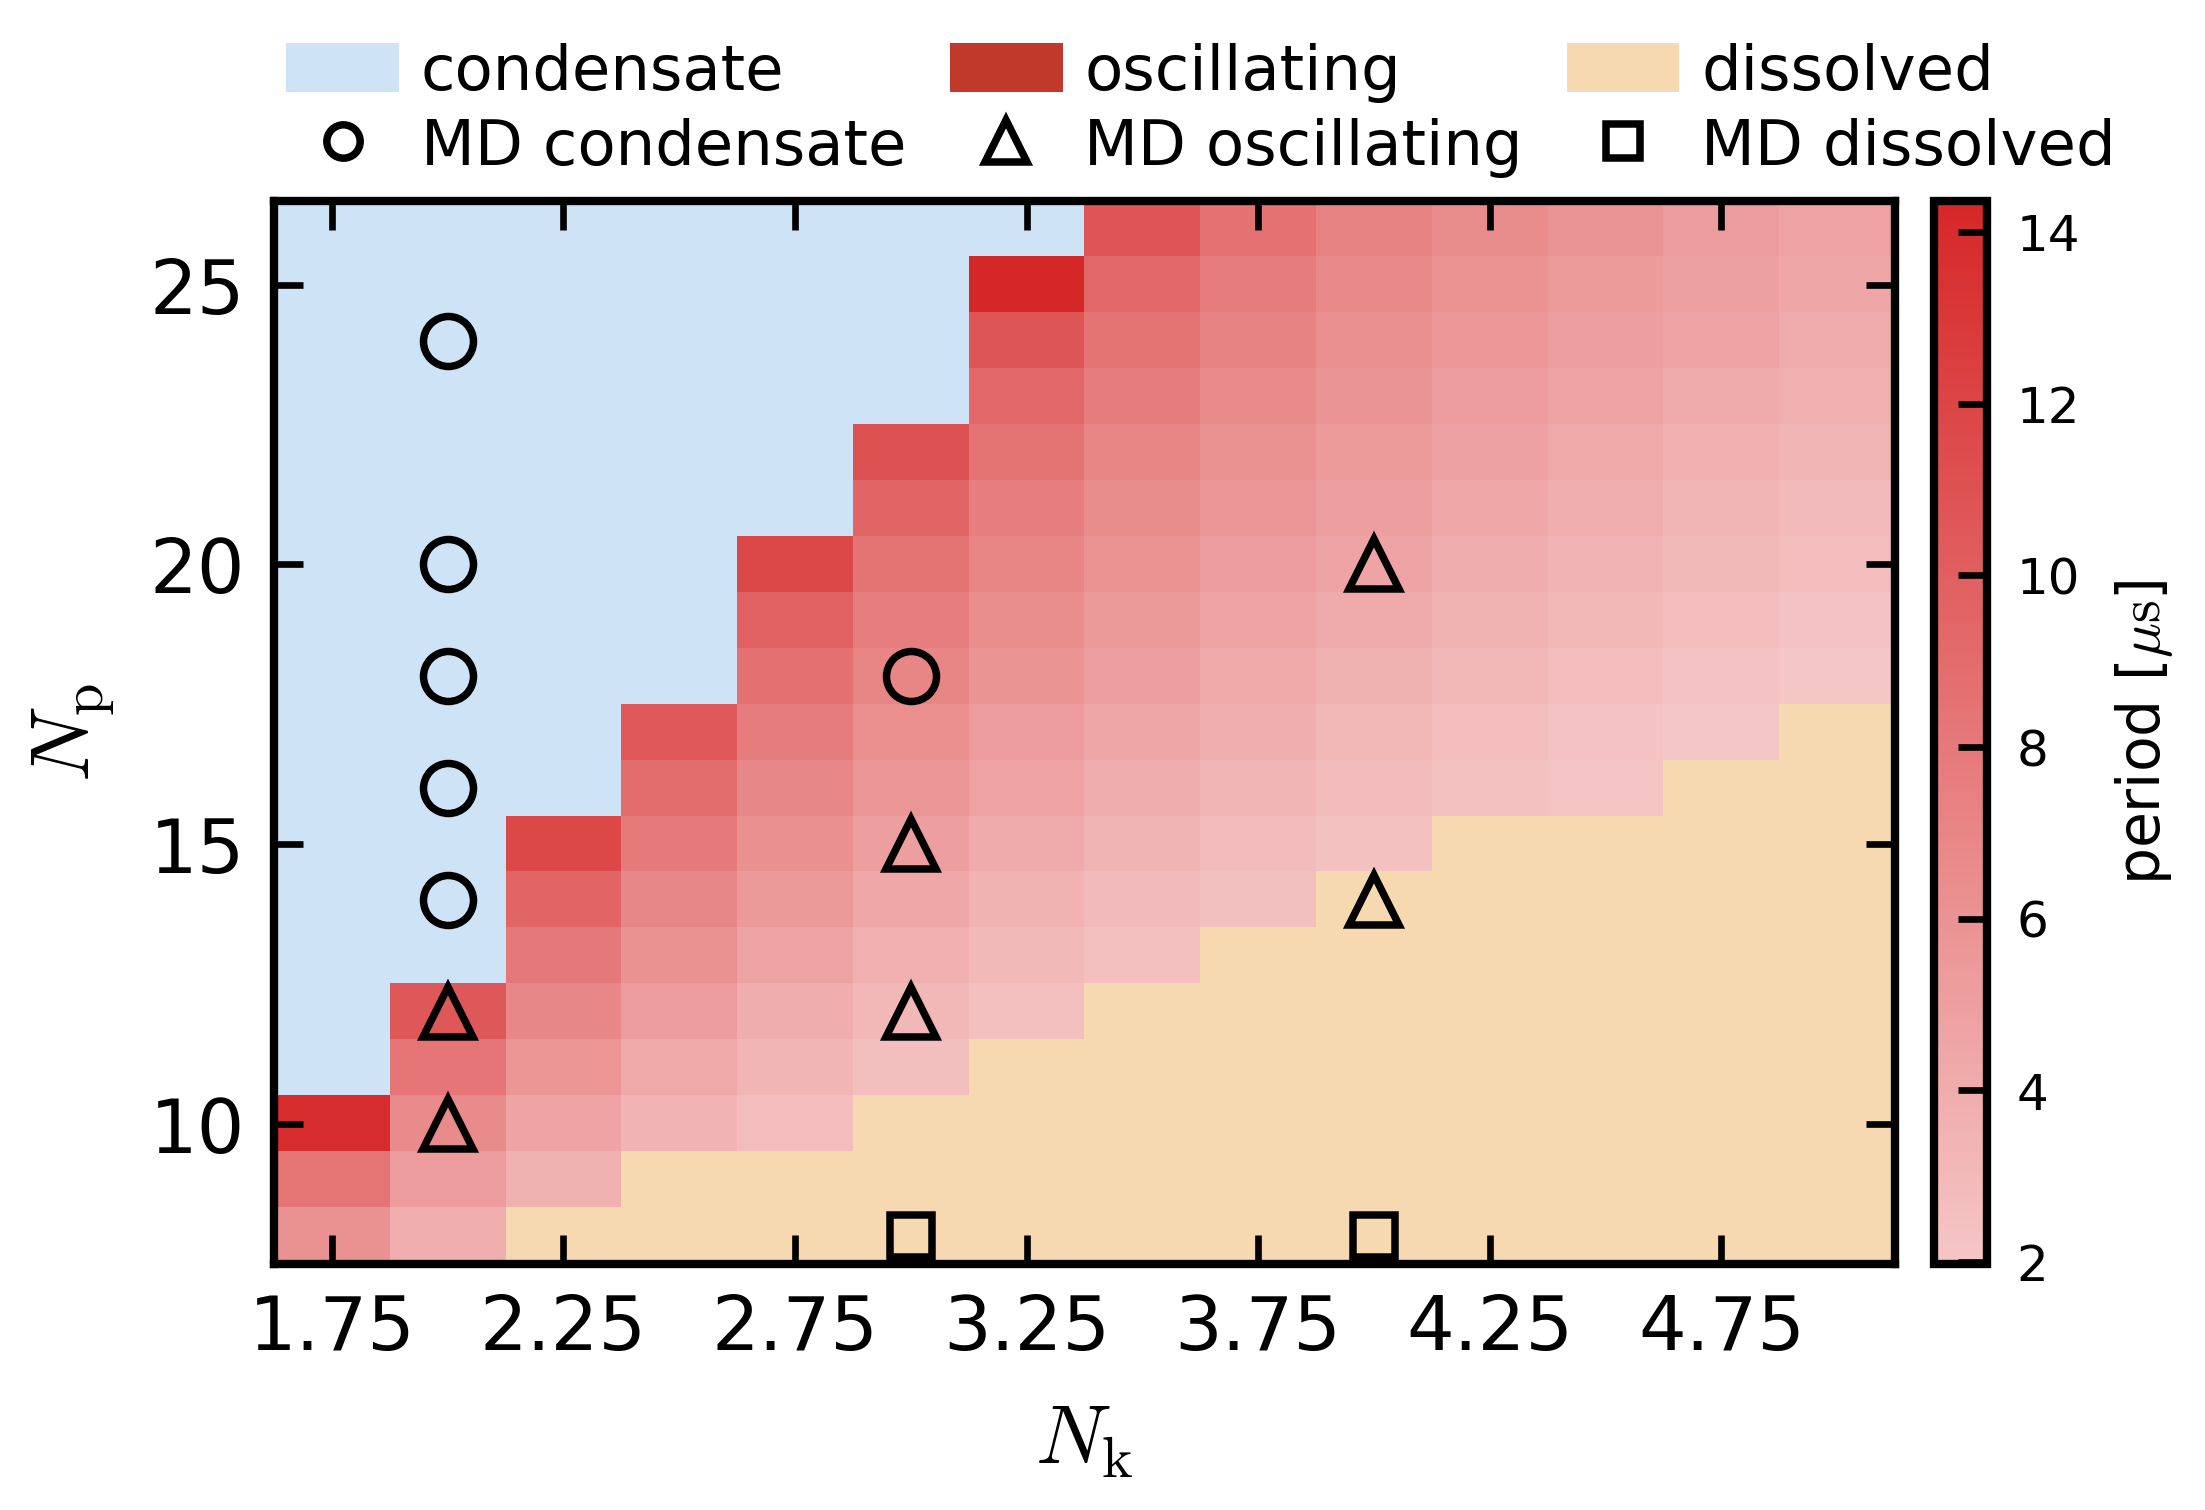

In [157]:
fig, ax = plt.subplots(1, 1, figsize=(4.2, 2.3))
ax.imshow(phase_image(color_period=True), origin='lower', aspect='auto', interpolation='nearest')
if SHOW_BISTABLE:
    hatch_bistable(ax)

sm = ScalarMappable(norm=norm_per, cmap=cmap_per)
sm.set_array(P[is_osc])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r'period [$\mathrm{\mu s}$]', fontsize=7)
cbar.ax.tick_params(labelsize=6)

md_markers(ax)
phase_axes(ax)
handles = [Patch(fc=COL['steady'], label='condensate'), _mk('o', 'MD condensate'),
           Patch(fc=COL['oscillating'], label='oscillating'), _mk('^', 'MD oscillating', 1.0),
           Patch(fc=COL['dissolved'], label='dissolved'), _mk('s', 'MD dissolved')]
if SHOW_BISTABLE:
    handles.append(bist_patch)
ax.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.0, 1.01), ncol=3,
          borderaxespad=0.0, handleheight=0.85, labelspacing=0.25,
          columnspacing=0.7, handletextpad=0.35, framealpha=0, fontsize=7.5)
savefig('phase_diagram_MD_and_phase_field_with_period' + bist_suffix)

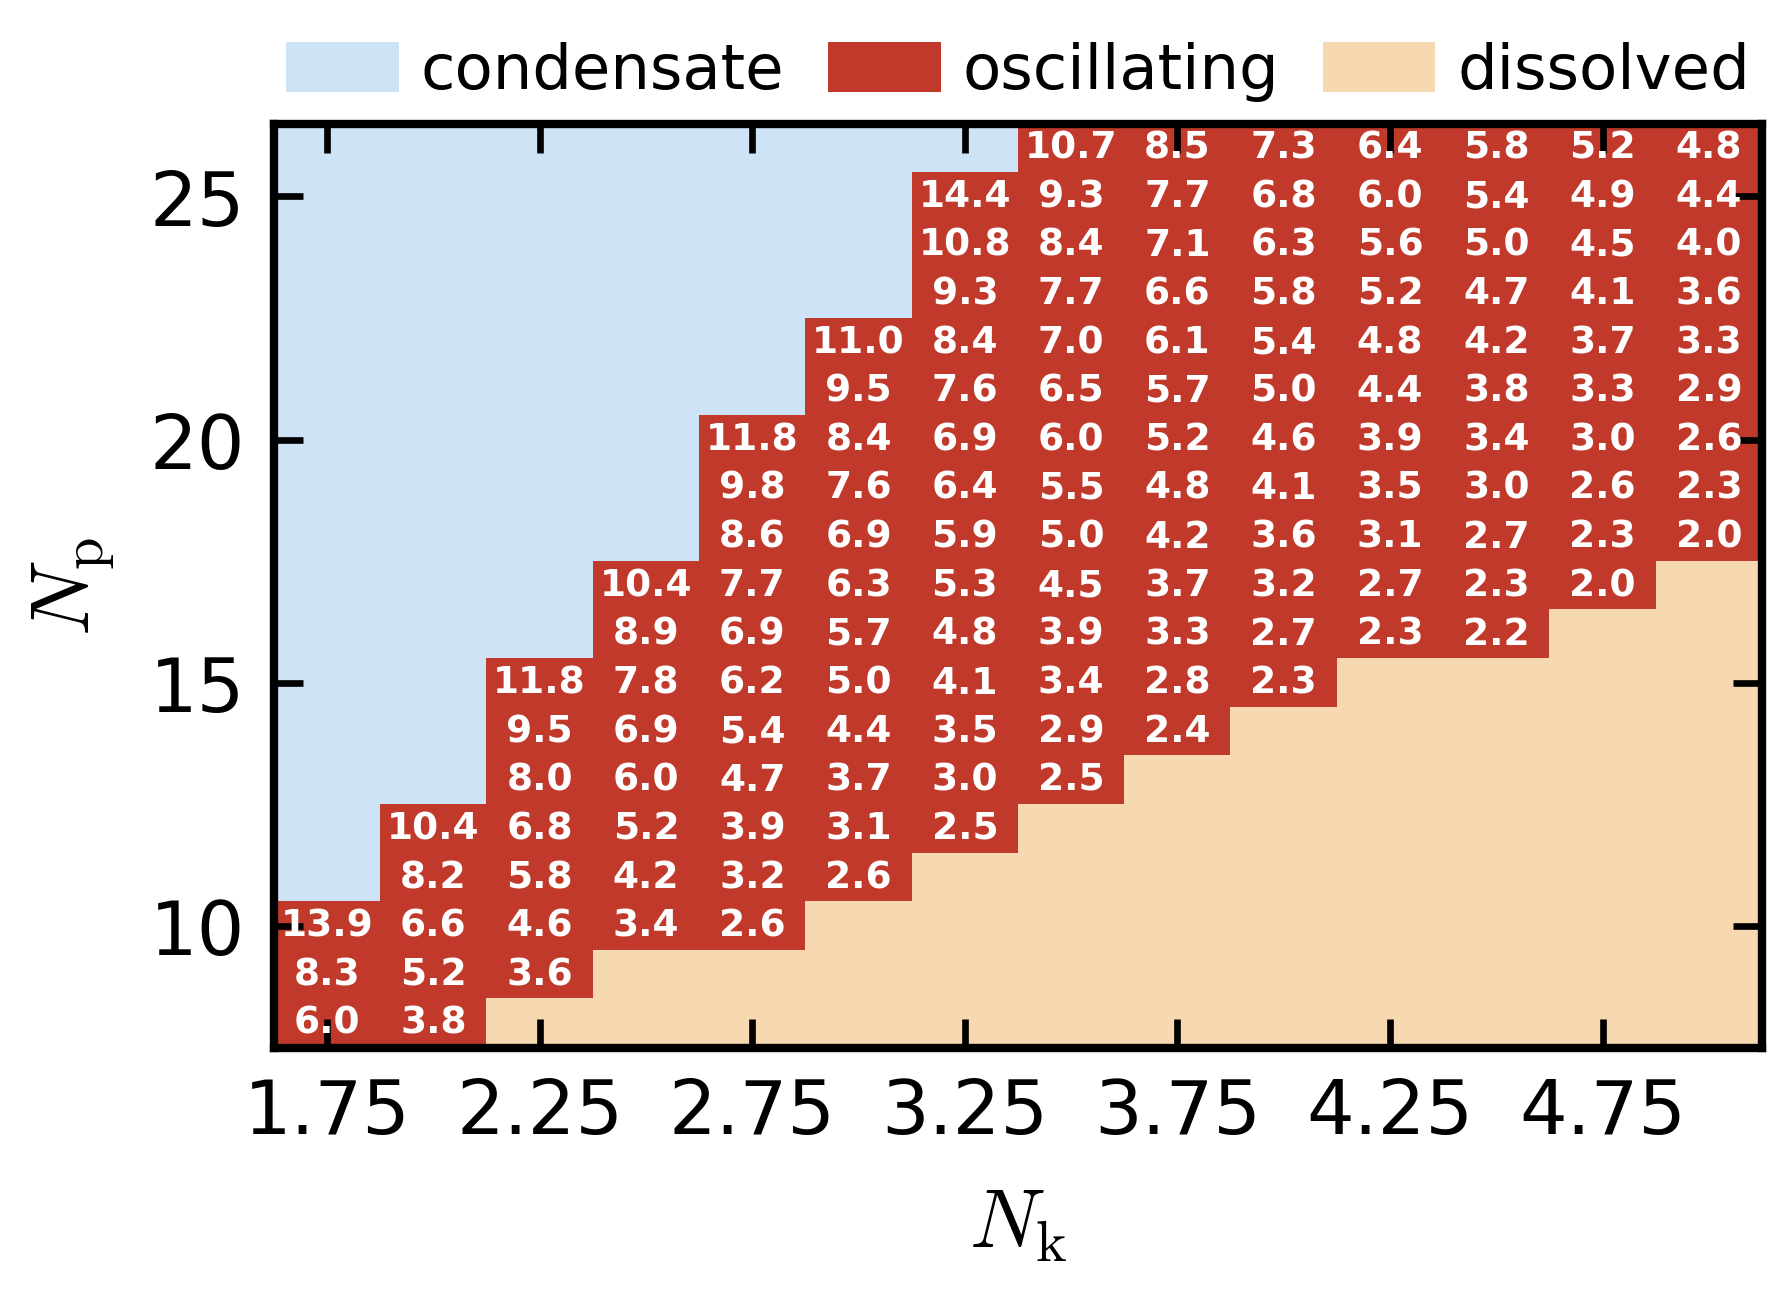

In [158]:
# model only, period written in the oscillating cells (not saved)
fig, ax = plt.subplots(1, 1, figsize=(3.2, 2))
ax.imshow(phase_image(color_period=False), origin='lower', aspect='auto', interpolation='nearest')
if SHOW_BISTABLE:
    hatch_bistable(ax)
for i, j in zip(*np.nonzero(is_osc)):
    ax.text(j, i, "%.1f" % P[i, j], ha='center', va='center', fontsize=4.5, color='white', fontweight='bold')

phase_axes(ax)
handles = [Patch(fc=COL['steady'], label='condensate'), Patch(fc=COL['oscillating'], label='oscillating'),
           Patch(fc=COL['dissolved'], label='dissolved')]
if SHOW_BISTABLE:
    handles.append(bist_patch)
ax.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.0, 1.01), ncol=3,
          borderaxespad=0.0, handleheight=0.85, labelspacing=0.25,
          columnspacing=0.7, handletextpad=0.35, framealpha=0, fontsize=7.5)
# savefig('phase_diagram_with_period_phase_field' + bist_suffix)